# Build a Logistic Regression Model

This notebook is kept separate from data cleaning. It will use a prepared modeling table, train a logistic regression model, validate it on later weeks, and keep the final holdout untouched until final evaluation.

## Modeling workflow

1. Load the prepared feature table.
2. Create time-aware train, validation, and locked-holdout splits.
3. Fit preprocessing only on the training data.
4. Train logistic regression.
5. Evaluate ranking, log loss, calibration, and performance across weeks.

In [6]:
from pathlib import Path

import pandas as pd

project_dir = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / 'data' / 'parquet_files' / 'train').is_dir()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        'Open Jupyter from the project folder or its notebooks folder.'
    )

train_dir = project_dir / 'data' / 'parquet_files' / 'train'
print('Project folder:', project_dir)

Project folder: d:\Home Credit - Credit Risk Model Stability


In [7]:
# Load the cleaned modeling table exported by the cleaning notebook
cleaned_modeling_path = project_dir / "data" / "processed" / "train_static_0_cleaned.parquet"
if not cleaned_modeling_path.exists():
    raise FileNotFoundError(
        "Run the final export cell in 08_data_cleaning.ipynb first: "
        f"{cleaned_modeling_path}"
    )

modeling_df = pd.read_parquet(cleaned_modeling_path)
print("Cleaned modeling table path:", cleaned_modeling_path)
print("Cleaned modeling table shape:", modeling_df.shape)
display(modeling_df.head())


Cleaned modeling table path: d:\Home Credit - Credit Risk Model Stability\data\processed\train_static_0_cleaned.parquet
Cleaned modeling table shape: (1526659, 101)


,case_id,WEEK_NUM,target,actualdpdtolerance_344P,amtinstpaidbefduel24m_4187115A,annuity_780A,annuitynextmonth_57A,applicationcnt_361L,applications30d_658L,applicationscnt_1086L,...,posfpd10lastmonth_333P,posfpd30lastmonth_3976960P,posfstqpd30lastmonth_3976962P,price_1097A,sellerplacecnt_915L,sellerplacescnt_216L,sumoutstandtotal_3546847A,totaldebt_9A,totalsettled_863A,twobodfilling_608L
0,0,0,0,NaN,NaN,1917.6,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
1,1,0,0,NaN,NaN,3134.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
2,2,0,0,NaN,NaN,4937.0,0.0,0.0,0.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO
3,3,0,0,NaN,NaN,4643.6,0.0,0.0,1.0,0.0,...,0.0,0.0,NaN,NaN,1.0,1.0,NaN,0.0,0.0,BO
4,4,0,1,NaN,NaN,3390.2,0.0,0.0,1.0,0.0,...,0.0,0.0,NaN,NaN,0.0,0.0,NaN,0.0,0.0,BO


In [8]:
# Keep the chronological evaluation design consistent with the cleaning notebook.
train_df = modeling_df.loc[modeling_df['WEEK_NUM'].between(0, 51)].copy()
validation_df = modeling_df.loc[modeling_df['WEEK_NUM'].between(52, 71)].copy()
test_holdout_df = modeling_df.loc[modeling_df['WEEK_NUM'].between(72, 91)].copy()

split_summary_df = pd.DataFrame({
    'split': ['train', 'validation', 'locked_holdout'],
    'rows': [len(train_df), len(validation_df), len(test_holdout_df)],
    'default_rate': [
        train_df['target'].mean(),
        validation_df['target'].mean(),
        test_holdout_df['target'].mean(),
    ],
})
display(split_summary_df)

,split,rows,default_rate
0,train,1065921,0.030893
1,validation,248535,0.041881
2,locked_holdout,212203,0.021941


In [9]:
# Build a leakage-safe preprocessing pipeline without scaling
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

excluded_columns = {"case_id", "WEEK_NUM", "target"}
feature_columns = [
    column for column in train_df.columns if column not in excluded_columns
]

numeric_feature_columns = [
    column
    for column in feature_columns
    if pd.api.types.is_numeric_dtype(train_df[column])
    and not pd.api.types.is_bool_dtype(train_df[column])
]
categorical_feature_columns = [
    column
    for column in feature_columns
    if column not in numeric_feature_columns
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("to_string", FunctionTransformer(
        lambda values: values.astype(str),
        feature_names_out="one-to-one",
    )),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", dtype="float32")),
])

preprocessing_pipeline = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_feature_columns),
        ("categorical", categorical_pipeline, categorical_feature_columns),
    ],
    remainder="drop",
)

X_train_prepared = preprocessing_pipeline.fit_transform(train_df[feature_columns])
X_validation_prepared = preprocessing_pipeline.transform(
    validation_df[feature_columns]
)
X_holdout_prepared = preprocessing_pipeline.transform(
    test_holdout_df[feature_columns]
)

if not np.isfinite(X_train_prepared.data).all():
    raise ValueError("Training preprocessing output contains non-finite values.")
if not np.isfinite(X_validation_prepared.data).all():
    raise ValueError("Validation preprocessing output contains non-finite values.")
if not np.isfinite(X_holdout_prepared.data).all():
    raise ValueError("Holdout preprocessing output contains non-finite values.")

y_train = train_df["target"].to_numpy()
y_validation = validation_df["target"].to_numpy()
y_holdout = test_holdout_df["target"].to_numpy()
prepared_feature_names = preprocessing_pipeline.get_feature_names_out()

print(f"Numeric input columns: {len(numeric_feature_columns)}")
print(f"Categorical input columns: {len(categorical_feature_columns)}")
print("Training matrix shape:", X_train_prepared.shape)
print("Validation matrix shape:", X_validation_prepared.shape)
print("Holdout matrix shape:", X_holdout_prepared.shape)
print("No scaling is applied in this first-stage pipeline.")
print("Preprocessing was fitted on training data only.")


Numeric input columns: 90
Categorical input columns: 8
Training matrix shape: (1065921, 114)
Validation matrix shape: (248535, 114)
Holdout matrix shape: (212203, 114)
No scaling is applied in this first-stage pipeline.
Preprocessing was fitted on training data only.


In [10]:
# Train logistic regression and evaluate future-period performance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score

logistic_model = LogisticRegression(
    C=1.0,
    max_iter=500,
    solver="lbfgs",
    random_state=42,
)

logistic_model.fit(X_train_prepared, y_train)

validation_probability = logistic_model.predict_proba(X_validation_prepared)[:, 1]
holdout_probability = logistic_model.predict_proba(X_holdout_prepared)[:, 1]

logistic_evaluation_df = pd.DataFrame({
    "split": ["validation", "locked_holdout"],
    "roc_auc": [
        roc_auc_score(y_validation, validation_probability),
        roc_auc_score(y_holdout, holdout_probability),
    ],
    "average_precision": [
        average_precision_score(y_validation, validation_probability),
        average_precision_score(y_holdout, holdout_probability),
    ],
    "log_loss": [
        log_loss(y_validation, validation_probability),
        log_loss(y_holdout, holdout_probability),
    ],
    "brier_score": [
        brier_score_loss(y_validation, validation_probability),
        brier_score_loss(y_holdout, holdout_probability),
    ],
    "mean_predicted_probability": [
        validation_probability.mean(),
        holdout_probability.mean(),
    ],
    "observed_default_rate": [
        y_validation.mean(),
        y_holdout.mean(),
    ],
})

print("Logistic regression training completed.")
display(logistic_evaluation_df)


c:\Users\DOWNLOAD\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic regression training completed.


,split,roc_auc,average_precision,log_loss,brier_score,mean_predicted_probability,observed_default_rate
0,validation,0.531896,0.049437,0.209138,0.042568,0.041228,0.041881
1,locked_holdout,0.572266,0.029902,0.124373,0.023939,0.036378,0.021941


## Logistic regression from scratch — Step 1

First, define the model inputs and initialize the parameters. We will not update the coefficients yet. The initial model gives every application the training default rate as its probability.

In [11]:
# Step 1: initialize parameters and calculate the first probabilities
import numpy as np

# X contains prepared training features; y contains the observed target values.
X_scratch = X_train_prepared
y_scratch = y_train.astype("float64")
n_rows, n_features = X_scratch.shape

# Start with zero feature coefficients.
scratch_weights = np.zeros(n_features, dtype="float64")

# Initialize the intercept from the training default rate.
training_default_rate = y_scratch.mean()
scratch_intercept = np.log(
    training_default_rate / (1.0 - training_default_rate)
)

def sigmoid(score):
    return 1.0 / (1.0 + np.exp(-score))

# First forward pass: z = b0 + Xw, then p = sigmoid(z).
scratch_linear_score = X_scratch @ scratch_weights + scratch_intercept
scratch_probability = sigmoid(scratch_linear_score)

print("Training rows:", n_rows)
print("Prepared features:", n_features)
print("Initial feature coefficients:", scratch_weights.shape)
print("Training default rate:", training_default_rate)
print("Initial intercept:", scratch_intercept)
print("First five linear scores:", np.asarray(scratch_linear_score[:5]).ravel())
print("First five probabilities:", np.asarray(scratch_probability[:5]).ravel())


Training rows: 1065921
Prepared features: 114
Initial feature coefficients: (114,)
Training default rate: 0.03089253331156812
Initial intercept: -3.445860996174887
First five linear scores: [-3.445861 -3.445861 -3.445861 -3.445861 -3.445861]
First five probabilities: [0.03089253 0.03089253 0.03089253 0.03089253 0.03089253]


In [12]:
# Inspect the initial scratch-model values
print("scratch_weights shape:", scratch_weights.shape)
print("Unique scratch_weights values:", np.unique(scratch_weights))
print("scratch_intercept:", scratch_intercept)
print("scratch_linear_score shape:", np.asarray(scratch_linear_score).shape)
print("scratch_probability shape:", np.asarray(scratch_probability).shape)

scratch_value_preview_df = pd.DataFrame({
    "row_position": np.arange(min(20, n_rows)),
    "linear_score_z": np.asarray(scratch_linear_score[:20]).ravel(),
    "default_probability": np.asarray(scratch_probability[:20]).ravel(),
    "observed_target": y_scratch[:20],
})
display(scratch_value_preview_df)

print("Linear-score summary:")
display(pd.Series(np.asarray(scratch_linear_score).ravel()).describe())
print("Probability summary:")
display(pd.Series(np.asarray(scratch_probability).ravel()).describe())


scratch_weights shape: (114,)
Unique scratch_weights values: [0.]
scratch_intercept: -3.445860996174887
scratch_linear_score shape: (1065921,)
scratch_probability shape: (1065921,)


,row_position,linear_score_z,default_probability,observed_target
0,0,-3.445861,0.030893,0.0
1,1,-3.445861,0.030893,0.0
2,2,-3.445861,0.030893,0.0
3,3,-3.445861,0.030893,0.0
4,4,-3.445861,0.030893,1.0
5,5,-3.445861,0.030893,0.0
6,6,-3.445861,0.030893,0.0
7,7,-3.445861,0.030893,0.0
8,8,-3.445861,0.030893,0.0
9,9,-3.445861,0.030893,0.0


Linear-score summary:


count    1.065921e+06
mean    -3.445861e+00
std      7.515458e-11
min     -3.445861e+00
25%     -3.445861e+00
50%     -3.445861e+00
75%     -3.445861e+00
max     -3.445861e+00
dtype: float64

Probability summary:


count    1.065921e+06
mean     3.089253e-02
std      3.564477e-13
min      3.089253e-02
25%      3.089253e-02
50%      3.089253e-02
75%      3.089253e-02
max      3.089253e-02
dtype: float64

## Logistic regression from scratch — Step 2: log loss

Compare each predicted probability with its observed target, then average the row-level losses. This measures the initial model before any coefficient update.

In [13]:
# Step 2: calculate binary log loss for the initial predictions
probability_epsilon = 1e-15
clipped_probability = np.clip(
    np.asarray(scratch_probability).ravel(),
    probability_epsilon,
    1.0 - probability_epsilon,
)

scratch_row_log_loss = -(
    y_scratch * np.log(clipped_probability)
    + (1.0 - y_scratch) * np.log(1.0 - clipped_probability)
)
scratch_average_log_loss = scratch_row_log_loss.mean()

scratch_log_loss_preview_df = pd.DataFrame({
    "row_position": np.arange(min(20, n_rows)),
    "observed_target": y_scratch[:20],
    "predicted_probability": clipped_probability[:20],
    "row_log_loss": scratch_row_log_loss[:20],
})

display(scratch_log_loss_preview_df)
print("Average initial log loss:", scratch_average_log_loss)


,row_position,observed_target,predicted_probability,row_log_loss
0,0,0.0,0.030893,0.031380
1,1,0.0,0.030893,0.031380
2,2,0.0,0.030893,0.031380
3,3,0.0,0.030893,0.031380
4,4,1.0,0.030893,3.477241
5,5,0.0,0.030893,0.031380
6,6,0.0,0.030893,0.031380
7,7,0.0,0.030893,0.031380
8,8,0.0,0.030893,0.031380
9,9,0.0,0.030893,0.031380


Average initial log loss: 0.1378311441169886


## Logistic regression from scratch — Step 3: one gradient update

The error for each row is `p - y`. We use those errors to calculate how each coefficient should change, then perform one update. This is not the full training loop yet.

In [14]:
# Step 3: calculate gradients and perform one update
row_error = np.asarray(scratch_probability).ravel() - y_scratch
gradient_intercept = row_error.mean()
gradient_weights = np.asarray(X_scratch.T @ row_error).ravel() / n_rows

learning_rate = 1e-7
updated_intercept = scratch_intercept - learning_rate * gradient_intercept
updated_weights = scratch_weights - learning_rate * gradient_weights

updated_linear_score = X_scratch @ updated_weights + updated_intercept
updated_probability = sigmoid(updated_linear_score)
updated_probability = np.clip(
    np.asarray(updated_probability).ravel(),
    probability_epsilon,
    1.0 - probability_epsilon,
)
updated_row_log_loss = -(
    y_scratch * np.log(updated_probability)
    + (1.0 - y_scratch) * np.log(1.0 - updated_probability)
)
updated_average_log_loss = updated_row_log_loss.mean()

gradient_preview_df = pd.DataFrame({
    "feature": prepared_feature_names[:20],
    "gradient": gradient_weights[:20],
    "updated_weight": updated_weights[:20],
})
display(gradient_preview_df)

print("Gradient intercept:", gradient_intercept)
print("Gradient norm:", np.linalg.norm(gradient_weights))
print("Learning rate:", learning_rate)
print("Initial average log loss:", scratch_average_log_loss)
print("Average log loss after one update:", updated_average_log_loss)


,feature,gradient,updated_weight
0,numeric__actualdpdtolerance_344P,-0.003279,3.278975e-10
1,numeric__amtinstpaidbefduel24m_4187115A,278.867504,-2.788675e-05
2,numeric__annuity_780A,-4.383673,4.383673e-07
3,numeric__annuitynextmonth_57A,-1.399866,1.399866e-07
4,numeric__applicationcnt_361L,-0.000003,2.970109e-13
5,numeric__applications30d_658L,-0.002873,2.872585e-10
6,numeric__applicationscnt_1086L,0.002414,-2.413736e-10
7,numeric__applicationscnt_464L,-0.005122,5.122022e-10
8,numeric__applicationscnt_629L,-0.001555,1.554528e-10
9,numeric__applicationscnt_867L,-0.002758,2.757679e-10


Gradient intercept: 5.132818534725154e-19
Gradient norm: 655.5674237378502
Learning rate: 1e-07
Initial average log loss: 0.1378311441169886
Average log loss after one update: 0.23243071833681614


## Scratch learning-rate search

Test candidate step sizes using the same initial gradient. We choose the candidate that produces the lowest log loss after one update.

In [15]:
# Test candidate learning rates before starting the full training loop
from scipy.special import expit

candidate_learning_rates = [1e-12, 1e-11, 1e-10, 1e-9, 1e-8, 1e-7]
learning_rate_results = []

for candidate_rate in candidate_learning_rates:
    candidate_intercept = scratch_intercept - candidate_rate * gradient_intercept
    candidate_weights = scratch_weights - candidate_rate * gradient_weights
    candidate_score = X_scratch @ candidate_weights + candidate_intercept
    candidate_probability = np.clip(
        expit(np.asarray(candidate_score).ravel()),
        probability_epsilon,
        1.0 - probability_epsilon,
    )
    candidate_loss = -(
        y_scratch * np.log(candidate_probability)
        + (1.0 - y_scratch) * np.log(1.0 - candidate_probability)
    ).mean()
    learning_rate_results.append({
        "learning_rate": candidate_rate,
        "average_log_loss": candidate_loss,
        "loss_decreased": candidate_loss < scratch_average_log_loss,
    })

learning_rate_results_df = (
    pd.DataFrame(learning_rate_results)
    .sort_values("average_log_loss")
    .reset_index(drop=True)
)
display(learning_rate_results_df)

best_learning_rate = learning_rate_results_df.iloc[0]["learning_rate"]
best_learning_rate_loss = learning_rate_results_df.iloc[0]["average_log_loss"]
print("Selected learning rate:", best_learning_rate)
print("Loss after selected one-step update:", best_learning_rate_loss)


,learning_rate,average_log_loss,loss_decreased
0,1.000000e-09,0.137467,True
1,1.000000e-10,0.137789,True
2,1.000000e-11,0.137827,True
3,1.000000e-12,0.137831,True
4,1.000000e-08,0.137952,False
5,1.000000e-07,0.232431,False


Selected learning rate: 1e-09
Loss after selected one-step update: 0.13746704899760673


## Scratch logistic regression — one update with backtracking

Try a gradient step and reduce the learning rate until the new log loss is lower than the current loss.

In [16]:
# One gradient update with backtracking line search
backtracking_rate = float(best_learning_rate)
backtracking_shrink = 0.5
max_backtracking_attempts = 20
current_loss = scratch_average_log_loss
accepted_update = False

for attempt in range(1, max_backtracking_attempts + 1):
    candidate_intercept = scratch_intercept - backtracking_rate * gradient_intercept
    candidate_weights = scratch_weights - backtracking_rate * gradient_weights
    candidate_score = X_scratch @ candidate_weights + candidate_intercept
    candidate_probability = np.clip(
        expit(np.asarray(candidate_score).ravel()),
        probability_epsilon,
        1.0 - probability_epsilon,
    )
    candidate_row_loss = -(
        y_scratch * np.log(candidate_probability)
        + (1.0 - y_scratch) * np.log(1.0 - candidate_probability)
    )
    candidate_loss = candidate_row_loss.mean()

    if candidate_loss < current_loss:
        accepted_update = True
        break

    backtracking_rate *= backtracking_shrink

if not accepted_update:
    raise RuntimeError(
        "Backtracking could not find a learning rate that reduced log loss."
    )

backtracking_intercept = candidate_intercept
backtracking_weights = candidate_weights
backtracking_probability = candidate_probability
backtracking_loss = candidate_loss

print("Accepted update:", accepted_update)
print("Backtracking attempts:", attempt)
print("Accepted learning rate:", backtracking_rate)
print("Loss before update:", current_loss)
print("Loss after update:", backtracking_loss)


Accepted update: True
Backtracking attempts: 1
Accepted learning rate: 1e-09
Loss before update: 0.1378311441169886
Loss after update: 0.13746704899760673


## Scratch logistic regression — full training loop

This loop repeats the forward pass, loss, gradient, backtracking, and update. It uses a configurable subset first so the learning process can be inspected safely.

In [17]:
# Repeat gradient updates until the loss converges
scratch_max_rows = 100_000  # Set to None later to use every training row.
scratch_loop_rows = n_rows if scratch_max_rows is None else min(scratch_max_rows, n_rows)
X_loop = X_scratch[:scratch_loop_rows]
y_loop = y_scratch[:scratch_loop_rows]

loop_rows, loop_features = X_loop.shape
loop_weights = np.zeros(loop_features, dtype="float64")
loop_default_rate = y_loop.mean()
loop_intercept = np.log(loop_default_rate / (1.0 - loop_default_rate))
loop_learning_rate = float(best_learning_rate)
loop_loss_history = []
loop_max_iterations = 25
loop_tolerance = 1e-7
loop_backtracking_shrink = 0.5
loop_max_backtracking_attempts = 20

for iteration in range(1, loop_max_iterations + 1):
    loop_score = X_loop @ loop_weights + loop_intercept
    loop_probability = np.clip(
        expit(np.asarray(loop_score).ravel()),
        probability_epsilon,
        1.0 - probability_epsilon,
    )
    loop_row_loss = -(
        y_loop * np.log(loop_probability)
        + (1.0 - y_loop) * np.log(1.0 - loop_probability)
    )
    current_loop_loss = loop_row_loss.mean()
    loop_loss_history.append(current_loop_loss)

    loop_error = loop_probability - y_loop
    loop_gradient_intercept = loop_error.mean()
    loop_gradient_weights = np.asarray(X_loop.T @ loop_error).ravel() / loop_rows

    candidate_rate = loop_learning_rate
    accepted = False
    for _ in range(loop_max_backtracking_attempts):
        candidate_intercept = loop_intercept - candidate_rate * loop_gradient_intercept
        candidate_weights = loop_weights - candidate_rate * loop_gradient_weights
        candidate_score = X_loop @ candidate_weights + candidate_intercept
        candidate_probability = np.clip(
            expit(np.asarray(candidate_score).ravel()),
            probability_epsilon,
            1.0 - probability_epsilon,
        )
        candidate_loss = -(
            y_loop * np.log(candidate_probability)
            + (1.0 - y_loop) * np.log(1.0 - candidate_probability)
        ).mean()

        if candidate_loss < current_loop_loss:
            accepted = True
            break
        candidate_rate *= loop_backtracking_shrink

    if not accepted:
        print(f"Stopping at iteration {iteration}: no improving step found.")
        break

    loop_weights = candidate_weights
    loop_intercept = candidate_intercept
    loop_learning_rate = candidate_rate

    improvement = current_loop_loss - candidate_loss
    if improvement < loop_tolerance:
        loop_loss_history.append(candidate_loss)
        print(f"Converged at iteration {iteration}.")
        break

loop_loss_history_df = pd.DataFrame({
    "iteration": np.arange(len(loop_loss_history)),
    "average_log_loss": loop_loss_history,
})
display(loop_loss_history_df)
print("Rows used:", loop_rows)
print("Final loss:", loop_loss_history[-1])
print("Final learning rate:", loop_learning_rate)


,iteration,average_log_loss
0,0,0.140774
1,1,0.140298
2,2,0.139957
3,3,0.139794
4,4,0.139694
5,5,0.139630
6,6,0.139586
7,7,0.139556
8,8,0.139534
9,9,0.139516


Rows used: 100000
Final loss: 0.13939825158346184
Final learning rate: 1e-09


## Evaluate the scratch-trained model

Use the learned weights to score later data. No coefficient updates are made with validation or holdout rows.

In [18]:
# Evaluate scratch-model probabilities on each time split
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score

def scratch_predict_probability(features):
    scores = features @ loop_weights + loop_intercept
    return np.clip(
        expit(np.asarray(scores).ravel()),
        probability_epsilon,
        1.0 - probability_epsilon,
    )

scratch_train_probability = scratch_predict_probability(X_loop)
scratch_validation_probability = scratch_predict_probability(X_validation_prepared)
scratch_holdout_probability = scratch_predict_probability(X_holdout_prepared)

scratch_evaluation_df = pd.DataFrame({
    "split": ["scratch_train_sample", "validation", "locked_holdout"],
    "rows": [len(y_loop), len(y_validation), len(y_holdout)],
    "roc_auc": [
        roc_auc_score(y_loop, scratch_train_probability),
        roc_auc_score(y_validation, scratch_validation_probability),
        roc_auc_score(y_holdout, scratch_holdout_probability),
    ],
    "average_precision": [
        average_precision_score(y_loop, scratch_train_probability),
        average_precision_score(y_validation, scratch_validation_probability),
        average_precision_score(y_holdout, scratch_holdout_probability),
    ],
    "log_loss": [
        log_loss(y_loop, scratch_train_probability),
        log_loss(y_validation, scratch_validation_probability),
        log_loss(y_holdout, scratch_holdout_probability),
    ],
})

display(scratch_evaluation_df)
print("Validation and holdout evaluation did not update the scratch weights.")


,split,rows,roc_auc,average_precision,log_loss
0,scratch_train_sample,100000,0.575397,0.040593,0.139393
1,validation,248535,0.595480,0.068237,0.174587
2,locked_holdout,212203,0.630899,0.041095,0.104067


Validation and holdout evaluation did not update the scratch weights.


## Visualize the sigmoid: linear score `z` to probability

The model first computes `z = b0 + b1*x1 + ...`. The sigmoid converts that score into a default probability between 0 and 1.

- Negative `z`: probability below 0.5
- `z = 0`: probability exactly 0.5
- Positive `z`: probability above 0.5


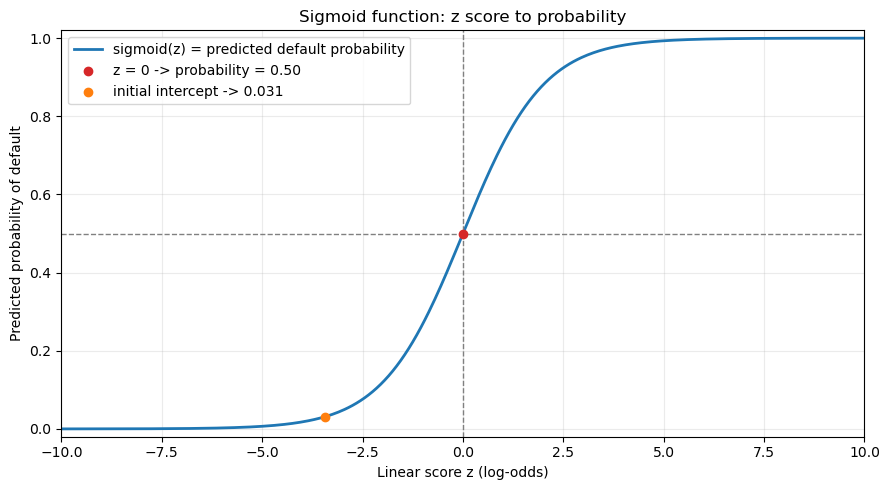

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# A range of possible linear scores (z = log-odds).
z_values = np.linspace(-10, 10, 401)
sigmoid_probabilities = 1.0 / (1.0 + np.exp(-z_values))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    z_values,
    sigmoid_probabilities,
    color="tab:blue",
    linewidth=2,
    label="sigmoid(z) = predicted default probability",
)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.scatter([0], [0.5], color="tab:red", zorder=3, label="z = 0 -> probability = 0.50")

# Show the initial intercept-based prediction when the earlier scratch cell exists.
if "scratch_intercept" in globals():
    initial_probability = float(1.0 / (1.0 + np.exp(-scratch_intercept)))
    ax.scatter(
        [scratch_intercept],
        [initial_probability],
        color="tab:orange",
        zorder=4,
        label=f"initial intercept -> {initial_probability:.3f}",
    )

ax.set_title("Sigmoid function: z score to probability")
ax.set_xlabel("Linear score z (log-odds)")
ax.set_ylabel("Predicted probability of default")
ax.set_xlim(-10, 10)
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


## Experiment: feature count and application count

This experiment changes the number of rows and feature columns. The initial model starts with zero feature weights, so its intercept is the log-odds of the selected rows' default rate.

The final case uses all available training applications. The table includes the requested and actually used counts.


In [21]:
import numpy as np
import pandas as pd

if "X_train_prepared" not in globals() or "y_train" not in globals():
    raise NameError("Run the preprocessing cells first so X_train_prepared and y_train exist.")

experiment_feature_requests = [1, 3, 10, X_train_prepared.shape[1]]
experiment_application_requests = [1, 3, 10, 100, 1_000, 100_000, "all"]
experiment_rows_available = int(X_train_prepared.shape[0])
experiment_columns_available = int(X_train_prepared.shape[1])
experiment_learning_rate = float(globals().get("best_learning_rate", 1e-12))

def _sigmoid_stable(values):
    values = np.asarray(values, dtype=np.float64)
    values = np.clip(values, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-values))

experiment_rows = []
for requested_features in experiment_feature_requests:
    used_features = min(int(requested_features), experiment_columns_available)
    X_feature_subset = X_train_prepared[:, :used_features]
    for requested_applications in experiment_application_requests:
        requested_count = experiment_rows_available if requested_applications == "all" else int(requested_applications)
        used_applications = min(requested_count, experiment_rows_available)
        X_subset = X_feature_subset[:used_applications]
        y_subset = np.asarray(y_train[:used_applications], dtype=np.float64)
        default_rate = float(np.mean(y_subset))
        clipped_rate = float(np.clip(default_rate, 1e-12, 1.0 - 1e-12))
        initial_intercept = float(np.log(clipped_rate / (1.0 - clipped_rate)))
        initial_z = initial_intercept
        initial_probability = float(_sigmoid_stable(initial_z))

        # One small gradient step shows when selected features begin affecting z.
        errors = np.full(used_applications, initial_probability) - y_subset
        gradient_intercept = float(np.mean(errors))
        gradient_weights = np.asarray(X_subset.T @ errors).ravel() / used_applications
        updated_intercept = initial_intercept - experiment_learning_rate * gradient_intercept
        updated_weights = -experiment_learning_rate * gradient_weights
        updated_z_first_row = float((X_subset[:1] @ updated_weights)[0] + updated_intercept)
        updated_probability_first_row = float(_sigmoid_stable(updated_z_first_row))

        experiment_rows.append({
            "features_requested": int(requested_features),
            "features_used": used_features,
            "applications_requested": requested_count,
            "applications_used": used_applications,
            "default_rate": default_rate,
            "initial_intercept": initial_intercept,
            "initial_z": initial_z,
            "initial_probability": initial_probability,
            "one_step_intercept": float(updated_intercept),
            "one_step_z_first_row": updated_z_first_row,
            "one_step_probability_first_row": updated_probability_first_row,
        })

size_feature_experiment_df = pd.DataFrame(experiment_rows)
size_feature_experiment_df["applications_capped"] = (size_feature_experiment_df["applications_requested"] > size_feature_experiment_df["applications_used"])
print(f"Available training rows: {experiment_rows_available:,}")
print(f"Available prepared features: {experiment_columns_available:,}")
print(f"Experiment learning rate for one illustrative step: {experiment_learning_rate:g}")

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(size_feature_experiment_df.round(6))


Available training rows: 1,065,921
Available prepared features: 114
Experiment learning rate for one illustrative step: 1e-09


,features_requested,features_used,applications_requested,applications_used,default_rate,initial_intercept,initial_z,initial_probability,one_step_intercept,one_step_z_first_row,one_step_probability_first_row,applications_capped
0,1,1,1,1,0.000000,-27.631021,-27.631021,0.000000,-27.631021,-27.631021,0.000000,False
1,1,1,3,3,0.000000,-27.631021,-27.631021,0.000000,-27.631021,-27.631021,0.000000,False
2,1,1,10,10,0.100000,-2.197225,-2.197225,0.100000,-2.197225,-2.197225,0.100000,False
3,1,1,100,100,0.010000,-4.595120,-4.595120,0.010000,-4.595120,-4.595120,0.010000,False
4,1,1,1000,1000,0.042000,-3.127178,-3.127178,0.042000,-3.127178,-3.127178,0.042000,False
5,1,1,100000,100000,0.031750,-3.417598,-3.417598,0.031750,-3.417598,-3.417598,0.031750,False
6,1,1,1065921,1065921,0.030893,-3.445861,-3.445861,0.030893,-3.445861,-3.445861,0.030893,False
7,3,3,1,1,0.000000,-27.631021,-27.631021,0.000000,-27.631021,-27.631021,0.000000,False
8,3,3,3,3,0.000000,-27.631021,-27.631021,0.000000,-27.631021,-27.631021,0.000000,False
9,3,3,10,10,0.100000,-2.197225,-2.197225,0.100000,-2.197225,-2.197325,0.099991,False


## Repeat the experiment for 10 gradient iterations

The previous experiment performed one illustrative update. This cell repeats the same gradient-descent process 10 times for each feature/application combination so we can observe the learned intercept, first-row score, probability, and log loss.


In [22]:
import numpy as np
import pandas as pd

if "X_train_prepared" not in globals() or "y_train" not in globals():
    raise NameError("Run the preprocessing cells first so X_train_prepared and y_train exist.")

ten_iteration_count = 10
ten_iteration_learning_rate = float(globals().get("best_learning_rate", 1e-12))
ten_iteration_feature_requests = [1, 3, 10, X_train_prepared.shape[1]]
ten_iteration_application_requests = [1, 3, 10, 100, 1_000, 100_000, "all"]
ten_iteration_rows_available = int(X_train_prepared.shape[0])
ten_iteration_columns_available = int(X_train_prepared.shape[1])
y_train_array = np.asarray(y_train, dtype=np.float64)

def _ten_iteration_sigmoid(values):
    values = np.asarray(values, dtype=np.float64)
    values = np.clip(values, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-values))

ten_iteration_rows = []
for requested_features in ten_iteration_feature_requests:
    used_features = min(int(requested_features), ten_iteration_columns_available)
    X_feature_subset = X_train_prepared[:, :used_features]
    for requested_applications in ten_iteration_application_requests:
        requested_count = ten_iteration_rows_available if requested_applications == "all" else int(requested_applications)
        used_applications = min(requested_count, ten_iteration_rows_available)
        X_subset = X_feature_subset[:used_applications]
        y_subset = y_train_array[:used_applications]
        default_rate = float(np.mean(y_subset))
        clipped_rate = float(np.clip(default_rate, 1e-12, 1.0 - 1e-12))
        intercept = float(np.log(clipped_rate / (1.0 - clipped_rate)))
        weights = np.zeros(used_features, dtype=np.float64)
        initial_probability = float(_ten_iteration_sigmoid(intercept))
        initial_loss = float(-np.mean(y_subset * np.log(np.clip(initial_probability, 1e-12, 1.0 - 1e-12)) + (1.0 - y_subset) * np.log(np.clip(1.0 - initial_probability, 1e-12, 1.0 - 1e-12))))

        for iteration in range(ten_iteration_count):
            z_values = np.asarray(X_subset @ weights).ravel() + intercept
            probabilities = _ten_iteration_sigmoid(z_values)
            errors = probabilities - y_subset
            gradient_intercept = float(np.mean(errors))
            gradient_weights = np.asarray(X_subset.T @ errors).ravel() / used_applications
            intercept -= ten_iteration_learning_rate * gradient_intercept
            weights -= ten_iteration_learning_rate * gradient_weights

        final_z_values = np.asarray(X_subset @ weights).ravel() + intercept
        final_probabilities = _ten_iteration_sigmoid(final_z_values)
        final_loss = float(-np.mean(y_subset * np.log(np.clip(final_probabilities, 1e-12, 1.0 - 1e-12)) + (1.0 - y_subset) * np.log(np.clip(1.0 - final_probabilities, 1e-12, 1.0 - 1e-12))))
        ten_iteration_rows.append({
            "features_requested": int(requested_features),
            "features_used": used_features,
            "applications_requested": requested_count,
            "applications_used": used_applications,
            "default_rate": default_rate,
            "initial_intercept": float(np.log(clipped_rate / (1.0 - clipped_rate))),
            "final_intercept_after_10": float(intercept),
            "final_z_first_row": float(final_z_values[0]),
            "final_probability_first_row": float(final_probabilities[0]),
            "initial_log_loss": initial_loss,
            "final_log_loss_after_10": final_loss,
        })

ten_iteration_experiment_df = pd.DataFrame(ten_iteration_rows)
ten_iteration_experiment_df["applications_capped"] = ten_iteration_experiment_df["applications_requested"] > ten_iteration_experiment_df["applications_used"]
print(f"Iterations per experiment: {ten_iteration_count}")
print(f"Learning rate: {ten_iteration_learning_rate:g}")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ten_iteration_experiment_df.round(6))


Iterations per experiment: 10
Learning rate: 1e-09


,features_requested,features_used,applications_requested,applications_used,default_rate,initial_intercept,final_intercept_after_10,final_z_first_row,final_probability_first_row,initial_log_loss,final_log_loss_after_10,applications_capped
0,1,1,1,1,0.000000,-27.631021,-27.631021,-27.631021,0.000000,0.000000,0.000000,False
1,1,1,3,3,0.000000,-27.631021,-27.631021,-27.631021,0.000000,0.000000,0.000000,False
2,1,1,10,10,0.100000,-2.197225,-2.197225,-2.197225,0.100000,0.325083,0.325083,False
3,1,1,100,100,0.010000,-4.595120,-4.595120,-4.595120,0.010000,0.056002,0.056002,False
4,1,1,1000,1000,0.042000,-3.127178,-3.127178,-3.127178,0.042000,0.174249,0.174249,False
5,1,1,100000,100000,0.031750,-3.417598,-3.417598,-3.417598,0.031750,0.140774,0.140774,False
6,1,1,1065921,1065921,0.030893,-3.445861,-3.445861,-3.445861,0.030893,0.137831,0.137831,False
7,3,3,1,1,0.000000,-27.631021,-27.631021,-27.631021,0.000000,0.000000,0.000000,False
8,3,3,3,3,0.000000,-27.631021,-27.631021,-27.631021,0.000000,0.000000,0.000000,False
9,3,3,10,10,0.100000,-2.197225,-2.197225,-2.197715,0.099956,0.325083,0.325056,False


## Inspect every iteration

This table records iteration 0 (before any update) and iterations 1 through 10. Each row represents one feature-count/application-count experiment at one training iteration.


In [23]:
import numpy as np
import pandas as pd

history_iterations = 10
history_learning_rate = float(globals().get("best_learning_rate", 1e-12))
history_feature_requests = [1, 3, 10, X_train_prepared.shape[1]]
history_application_requests = [1, 3, 10, 100, 1_000, 100_000, "all"]
history_rows_available = int(X_train_prepared.shape[0])
history_columns_available = int(X_train_prepared.shape[1])
history_y = np.asarray(y_train, dtype=np.float64)

def _history_sigmoid(values):
    values = np.asarray(values, dtype=np.float64)
    values = np.clip(values, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-values))

def _history_log_loss(probabilities, targets):
    probabilities = np.clip(probabilities, 1e-12, 1.0 - 1e-12)
    return float(-np.mean(targets * np.log(probabilities) + (1.0 - targets) * np.log(1.0 - probabilities)))

history_rows = []
for requested_features in history_feature_requests:
    used_features = min(int(requested_features), history_columns_available)
    X_feature_subset = X_train_prepared[:, :used_features]
    for requested_applications in history_application_requests:
        requested_count = history_rows_available if requested_applications == "all" else int(requested_applications)
        used_applications = min(requested_count, history_rows_available)
        X_subset = X_feature_subset[:used_applications]
        y_subset = history_y[:used_applications]
        default_rate = float(np.mean(y_subset))
        clipped_rate = float(np.clip(default_rate, 1e-12, 1.0 - 1e-12))
        intercept = float(np.log(clipped_rate / (1.0 - clipped_rate)))
        weights = np.zeros(used_features, dtype=np.float64)

        for iteration in range(history_iterations + 1):
            z_values = np.asarray(X_subset @ weights).ravel() + intercept
            probabilities = _history_sigmoid(z_values)
            errors = probabilities - y_subset
            gradient_intercept = float(np.mean(errors))
            gradient_weights = np.asarray(X_subset.T @ errors).ravel() / used_applications
            history_rows.append({
                "features_used": used_features,
                "applications_requested": requested_count,
                "applications_used": used_applications,
                "iteration": iteration,
                "default_rate": default_rate,
                "intercept": float(intercept),
                "z_first_row": float(z_values[0]),
                "probability_first_row": float(probabilities[0]),
                "average_log_loss": _history_log_loss(probabilities, y_subset),
                "gradient_intercept": gradient_intercept,
                "gradient_norm": float(np.linalg.norm(gradient_weights)),
            })

            if iteration < history_iterations:
                intercept -= history_learning_rate * gradient_intercept
                weights -= history_learning_rate * gradient_weights

iteration_history_df = pd.DataFrame(history_rows)
print(f"Rows in detailed table: {len(iteration_history_df):,}")
print("Iteration 0 is before the first update; iteration 10 is after ten updates.")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 240):
    display(iteration_history_df.round(6))


Rows in detailed table: 308
Iteration 0 is before the first update; iteration 10 is after ten updates.


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1,1,1,0,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
1,1,1,1,1,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
2,1,1,1,2,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
3,1,1,1,3,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
4,1,1,1,4,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
5,1,1,1,5,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
6,1,1,1,6,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
7,1,1,1,7,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
8,1,1,1,8,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
9,1,1,1,9,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000


## Compact comparison: how loss changes by iteration

The long history table is useful for inspection but difficult to compare visually. These compact tables use rows for application counts and columns for iterations. Each table contains one feature-count setting. Lower log loss is better.


In [24]:
if "iteration_history_df" not in globals():
    raise NameError("Run the detailed iteration-history cell first.")

comparison_df = iteration_history_df.copy()
comparison_df["application_label"] = comparison_df["applications_used"].map(lambda value: f"{int(value):,}")

print("Average log loss by application count and iteration")
for feature_count in comparison_df["features_used"].drop_duplicates().tolist():
    loss_table = (
        comparison_df[comparison_df["features_used"] == feature_count]
        .pivot(index="application_label", columns="iteration", values="average_log_loss")
        .sort_index(key=lambda values: values.map(lambda value: int(value.replace(",", ""))))
    )
    display(loss_table.style.format("{:.6f}").set_caption(f"Features used: {feature_count:,}"))

print("First-row probability by application count and iteration")
for feature_count in comparison_df["features_used"].drop_duplicates().tolist():
    probability_table = (
        comparison_df[comparison_df["features_used"] == feature_count]
        .pivot(index="application_label", columns="iteration", values="probability_first_row")
        .sort_index(key=lambda values: values.map(lambda value: int(value.replace(",", ""))))
    )
    display(probability_table.style.format("{:.6f}").set_caption(f"Features used: {feature_count:,}"))


Average log loss by application count and iteration


iteration,0,1,2,3,4,5,6,7,8,9,10
application_label,,,,,,,,,,,
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.325083,0.325083,0.325083,0.325083,0.325083,0.325083,0.325083,0.325083,0.325083,0.325083,0.325083
100,0.056002,0.056002,0.056002,0.056002,0.056002,0.056002,0.056002,0.056002,0.056002,0.056002,0.056002
"1,000",0.174249,0.174249,0.174249,0.174249,0.174249,0.174249,0.174249,0.174249,0.174249,0.174249,0.174249
"100,000",0.140774,0.140774,0.140774,0.140774,0.140774,0.140774,0.140774,0.140774,0.140774,0.140774,0.140774
"1,065,921",0.137831,0.137831,0.137831,0.137831,0.137831,0.137831,0.137831,0.137831,0.137831,0.137831,0.137831


iteration,0,1,2,3,4,5,6,7,8,9,10
application_label,,,,,,,,,,,
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.325083,0.325080,0.325078,0.325075,0.325072,0.325069,0.325067,0.325064,0.325061,0.325059,0.325056
100,0.056002,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001
"1,000",0.174249,0.174249,0.174248,0.174248,0.174248,0.174248,0.174247,0.174247,0.174247,0.174247,0.174246
"100,000",0.140774,0.140647,0.140565,0.140510,0.140472,0.140446,0.140427,0.140413,0.140404,0.140396,0.140391
"1,065,921",0.137831,0.137758,0.137702,0.137659,0.137625,0.137598,0.137576,0.137559,0.137544,0.137533,0.137523


iteration,0,1,2,3,4,5,6,7,8,9,10
application_label,,,,,,,,,,,
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.325083,0.325080,0.325078,0.325075,0.325072,0.325069,0.325067,0.325064,0.325061,0.325059,0.325056
100,0.056002,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001,0.056001
"1,000",0.174249,0.174249,0.174248,0.174248,0.174248,0.174248,0.174247,0.174247,0.174247,0.174247,0.174246
"100,000",0.140774,0.140647,0.140565,0.140510,0.140472,0.140446,0.140427,0.140413,0.140404,0.140396,0.140391
"1,065,921",0.137831,0.137758,0.137702,0.137659,0.137625,0.137598,0.137576,0.137558,0.137544,0.137533,0.137523


iteration,0,1,2,3,4,5,6,7,8,9,10
application_label,,,,,,,,,,,
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.325083,0.322456,0.320117,0.317963,0.315966,0.314110,0.312381,0.310767,0.309258,0.307844,0.306516
100,0.056002,0.055966,0.055932,0.055898,0.055865,0.055833,0.055801,0.055770,0.055739,0.055708,0.055678
"1,000",0.174249,0.174228,0.174210,0.174194,0.174178,0.174163,0.174149,0.174134,0.174120,0.174106,0.174092
"100,000",0.140774,0.140298,0.139957,0.139794,0.139694,0.139630,0.139586,0.139556,0.139534,0.139516,0.139502
"1,065,921",0.137831,0.137467,0.137216,0.137029,0.136886,0.136776,0.136690,0.136620,0.136564,0.136517,0.136478


First-row probability by application count and iteration


iteration,0,1,2,3,4,5,6,7,8,9,10
application_label,,,,,,,,,,,
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000,0.100000
100,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000,0.010000
"1,000",0.042000,0.042000,0.042000,0.042000,0.042000,0.042000,0.042000,0.042000,0.042000,0.042000,0.042000
"100,000",0.031750,0.031750,0.031750,0.031750,0.031750,0.031750,0.031750,0.031750,0.031750,0.031750,0.031750
"1,065,921",0.030893,0.030893,0.030893,0.030893,0.030893,0.030893,0.030893,0.030893,0.030893,0.030893,0.030893


iteration,0,1,2,3,4,5,6,7,8,9,10
application_label,,,,,,,,,,,
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.100000,0.099991,0.099983,0.099976,0.099971,0.099966,0.099963,0.099960,0.099958,0.099956,0.099956
100,0.010000,0.010000,0.010000,0.010000,0.009999,0.009999,0.009999,0.009999,0.009999,0.009999,0.009999
"1,000",0.042000,0.041999,0.041998,0.041996,0.041995,0.041995,0.041994,0.041993,0.041992,0.041992,0.041991
"100,000",0.031750,0.031441,0.031195,0.030996,0.030832,0.030697,0.030583,0.030488,0.030407,0.030338,0.030280
"1,065,921",0.030893,0.030669,0.030474,0.030304,0.030154,0.030022,0.029904,0.029800,0.029706,0.029622,0.029546


iteration,0,1,2,3,4,5,6,7,8,9,10
application_label,,,,,,,,,,,
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.100000,0.099991,0.099983,0.099976,0.099971,0.099966,0.099963,0.099960,0.099958,0.099956,0.099956
100,0.010000,0.010000,0.010000,0.010000,0.009999,0.009999,0.009999,0.009999,0.009999,0.009999,0.009999
"1,000",0.042000,0.041999,0.041998,0.041997,0.041995,0.041995,0.041994,0.041993,0.041992,0.041992,0.041991
"100,000",0.031750,0.031441,0.031195,0.030996,0.030833,0.030697,0.030583,0.030488,0.030407,0.030339,0.030280
"1,065,921",0.030893,0.030669,0.030474,0.030304,0.030154,0.030022,0.029904,0.029799,0.029706,0.029621,0.029546


iteration,0,1,2,3,4,5,6,7,8,9,10
application_label,,,,,,,,,,,
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
10,0.100000,0.103492,0.105319,0.106462,0.107322,0.108050,0.108705,0.109308,0.109872,0.110404,0.110906
100,0.010000,0.009978,0.009961,0.009947,0.009938,0.009931,0.009928,0.009927,0.009928,0.009932,0.009937
"1,000",0.042000,0.041858,0.041802,0.041797,0.041822,0.041864,0.041917,0.041976,0.042038,0.042102,0.042166
"100,000",0.031750,0.031332,0.032223,0.032159,0.032469,0.032479,0.032613,0.032628,0.032681,0.032688,0.032704
"1,065,921",0.030893,0.030844,0.031055,0.031173,0.031251,0.031297,0.031317,0.031316,0.031298,0.031269,0.031230


## Full labeled iteration history

Use this view when you need every original column label. Each row is one experiment configuration at one iteration.


In [25]:
labeled_history_columns = [
    "features_used",
    "applications_requested",
    "applications_used",
    "iteration",
    "default_rate",
    "intercept",
    "z_first_row",
    "probability_first_row",
    "average_log_loss",
    "gradient_intercept",
    "gradient_norm",
]

full_labeled_iteration_history_df = iteration_history_df[labeled_history_columns].copy()
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 260):
    display(full_labeled_iteration_history_df.round(6))


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1,1,1,0,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
1,1,1,1,1,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
2,1,1,1,2,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
3,1,1,1,3,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
4,1,1,1,4,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
5,1,1,1,5,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
6,1,1,1,6,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
7,1,1,1,7,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
8,1,1,1,8,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
9,1,1,1,9,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000


## Focused example: 1 feature and 1 application

Start with the smallest experiment so the effect of each iteration is easy to follow. This shows the complete history from iteration 0 through iteration 10.


In [26]:
one_application_one_feature_df = full_labeled_iteration_history_df.query(
    "features_used == 1 and applications_used == 1"
).reset_index(drop=True)

print("One feature, one application: iterations 0 through 10")
display(one_application_one_feature_df.round(6))


One feature, one application: iterations 0 through 10


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1,1,1,0,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
1,1,1,1,1,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
2,1,1,1,2,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
3,1,1,1,3,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
4,1,1,1,4,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
5,1,1,1,5,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
6,1,1,1,6,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
7,1,1,1,7,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
8,1,1,1,8,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0
9,1,1,1,9,0.0,-27.631021,-27.631021,0.0,0.0,0.0,0.0


## Separate tables for every remaining combination

Each table below contains one feature/application configuration and iterations 0 through 10. The 1-feature/1-application table is shown in the previous cell and is excluded here to avoid duplication.


In [27]:
separate_table_feature_counts = full_labeled_iteration_history_df["features_used"].drop_duplicates().tolist()
separate_table_application_counts = full_labeled_iteration_history_df["applications_used"].drop_duplicates().tolist()

for feature_count in separate_table_feature_counts:
    for application_count in separate_table_application_counts:
        if feature_count == 1 and application_count == 1:
            continue
        combination_table = full_labeled_iteration_history_df.query(
            "features_used == @feature_count and applications_used == @application_count"
        ).reset_index(drop=True)
        display(
            combination_table.style
            .format("{:.6f}")
            .set_caption(
                f"Features: {int(feature_count):,} | Applications: {int(application_count):,}"
            )
        )


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1.000000,3.000000,3.000000,0.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
1,1.000000,3.000000,3.000000,1.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
2,1.000000,3.000000,3.000000,2.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
3,1.000000,3.000000,3.000000,3.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
4,1.000000,3.000000,3.000000,4.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
5,1.000000,3.000000,3.000000,5.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
6,1.000000,3.000000,3.000000,6.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
7,1.000000,3.000000,3.000000,7.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
8,1.000000,3.000000,3.000000,8.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000
9,1.000000,3.000000,3.000000,9.000000,0.000000,-27.631021,-27.631021,0.000000,0.000000,0.000000,0.000000


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1.000000,10.000000,10.000000,0.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
1,1.000000,10.000000,10.000000,1.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
2,1.000000,10.000000,10.000000,2.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
3,1.000000,10.000000,10.000000,3.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
4,1.000000,10.000000,10.000000,4.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
5,1.000000,10.000000,10.000000,5.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
6,1.000000,10.000000,10.000000,6.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
7,1.000000,10.000000,10.000000,7.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
8,1.000000,10.000000,10.000000,8.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000
9,1.000000,10.000000,10.000000,9.000000,0.100000,-2.197225,-2.197225,0.100000,0.325083,0.000000,0.000000


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1.000000,100.000000,100.000000,0.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
1,1.000000,100.000000,100.000000,1.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
2,1.000000,100.000000,100.000000,2.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
3,1.000000,100.000000,100.000000,3.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
4,1.000000,100.000000,100.000000,4.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
5,1.000000,100.000000,100.000000,5.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
6,1.000000,100.000000,100.000000,6.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
7,1.000000,100.000000,100.000000,7.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
8,1.000000,100.000000,100.000000,8.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000
9,1.000000,100.000000,100.000000,9.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,0.000000


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1.000000,1000.000000,1000.000000,0.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
1,1.000000,1000.000000,1000.000000,1.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
2,1.000000,1000.000000,1000.000000,2.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
3,1.000000,1000.000000,1000.000000,3.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
4,1.000000,1000.000000,1000.000000,4.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
5,1.000000,1000.000000,1000.000000,5.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
6,1.000000,1000.000000,1000.000000,6.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
7,1.000000,1000.000000,1000.000000,7.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
8,1.000000,1000.000000,1000.000000,8.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000
9,1.000000,1000.000000,1000.000000,9.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,0.000000


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1.000000,100000.000000,100000.000000,0.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,-0.000000,0.001027
1,1.000000,100000.000000,100000.000000,1.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027
2,1.000000,100000.000000,100000.000000,2.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027
3,1.000000,100000.000000,100000.000000,3.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027
4,1.000000,100000.000000,100000.000000,4.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027
5,1.000000,100000.000000,100000.000000,5.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027
6,1.000000,100000.000000,100000.000000,6.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027
7,1.000000,100000.000000,100000.000000,7.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027
8,1.000000,100000.000000,100000.000000,8.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027
9,1.000000,100000.000000,100000.000000,9.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,0.000000,0.001027


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,1.000000,1065921.000000,1065921.000000,0.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
1,1.000000,1065921.000000,1065921.000000,1.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
2,1.000000,1065921.000000,1065921.000000,2.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
3,1.000000,1065921.000000,1065921.000000,3.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
4,1.000000,1065921.000000,1065921.000000,4.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
5,1.000000,1065921.000000,1065921.000000,5.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
6,1.000000,1065921.000000,1065921.000000,6.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
7,1.000000,1065921.000000,1065921.000000,7.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
8,1.000000,1065921.000000,1065921.000000,8.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279
9,1.000000,1065921.000000,1065921.000000,9.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,0.003279


... (17 outputs left out)

,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,114.000000,100.000000,100.000000,0.000000,0.010000,-4.595120,-4.595120,0.010000,0.056002,0.000000,188.783440
1,114.000000,100.000000,100.000000,1.000000,0.010000,-4.595120,-4.597339,0.009978,0.055966,-0.000065,186.024376
2,114.000000,100.000000,100.000000,2.000000,0.010000,-4.595120,-4.599101,0.009961,0.055932,-0.000123,183.691868
3,114.000000,100.000000,100.000000,3.000000,0.010000,-4.595120,-4.600453,0.009947,0.055898,-0.000176,181.709151
4,114.000000,100.000000,100.000000,4.000000,0.010000,-4.595120,-4.601438,0.009938,0.055865,-0.000223,180.013377
5,114.000000,100.000000,100.000000,5.000000,0.010000,-4.595120,-4.602093,0.009931,0.055833,-0.000266,178.553108
6,114.000000,100.000000,100.000000,6.000000,0.010000,-4.595120,-4.602452,0.009928,0.055801,-0.000304,177.286254
7,114.000000,100.000000,100.000000,7.000000,0.010000,-4.595120,-4.602543,0.009927,0.055770,-0.000340,176.178365
8,114.000000,100.000000,100.000000,8.000000,0.010000,-4.595120,-4.602395,0.009928,0.055739,-0.000371,175.201243
9,114.000000,100.000000,100.000000,9.000000,0.010000,-4.595120,-4.602029,0.009932,0.055708,-0.000400,174.331792


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,114.000000,1000.000000,1000.000000,0.000000,0.042000,-3.127178,-3.127178,0.042000,0.174249,0.000000,150.183869
1,114.000000,1000.000000,1000.000000,1.000000,0.042000,-3.127178,-3.130725,0.041858,0.174228,-0.000285,134.833340
2,114.000000,1000.000000,1000.000000,2.000000,0.042000,-3.127178,-3.132115,0.041802,0.174210,-0.000451,128.242020
3,114.000000,1000.000000,1000.000000,3.000000,0.042000,-3.127178,-3.132239,0.041797,0.174194,-0.000547,125.060364
4,114.000000,1000.000000,1000.000000,4.000000,0.042000,-3.127178,-3.131617,0.041822,0.174178,-0.000601,123.162393
5,114.000000,1000.000000,1000.000000,5.000000,0.042000,-3.127178,-3.130557,0.041864,0.174163,-0.000631,121.750440
6,114.000000,1000.000000,1000.000000,6.000000,0.042000,-3.127178,-3.129242,0.041917,0.174149,-0.000647,120.531076
7,114.000000,1000.000000,1000.000000,7.000000,0.042000,-3.127178,-3.127779,0.041976,0.174134,-0.000653,119.396652
8,114.000000,1000.000000,1000.000000,8.000000,0.042000,-3.127178,-3.126236,0.042038,0.174120,-0.000655,118.307380
9,114.000000,1000.000000,1000.000000,9.000000,0.042000,-3.127178,-3.124651,0.042102,0.174106,-0.000653,117.248230


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,114.000000,100000.000000,100000.000000,0.000000,0.031750,-3.417598,-3.417598,0.031750,0.140774,-0.000000,1156.590891
1,114.000000,100000.000000,100000.000000,1.000000,0.031750,-3.417598,-3.431273,0.031332,0.140298,-0.003802,793.452612
2,114.000000,100000.000000,100000.000000,2.000000,0.031750,-3.417598,-3.402323,0.032223,0.139957,-0.000952,495.737326
3,114.000000,100000.000000,100000.000000,3.000000,0.031750,-3.417598,-3.404382,0.032159,0.139794,-0.002025,367.190472
4,114.000000,100000.000000,100000.000000,4.000000,0.031750,-3.417598,-3.394456,0.032469,0.139694,-0.001158,281.003109
5,114.000000,100000.000000,100000.000000,5.000000,0.031750,-3.417598,-3.394135,0.032479,0.139630,-0.001513,224.246193
6,114.000000,100000.000000,100000.000000,6.000000,0.031750,-3.417598,-3.389880,0.032613,0.139586,-0.001176,184.295899
7,114.000000,100000.000000,100000.000000,7.000000,0.031750,-3.417598,-3.389405,0.032628,0.139556,-0.001288,156.206192
8,114.000000,100000.000000,100000.000000,8.000000,0.031750,-3.417598,-3.387722,0.032681,0.139534,-0.001159,136.126077
9,114.000000,100000.000000,100000.000000,9.000000,0.031750,-3.417598,-3.387509,0.032688,0.139516,-0.001188,121.685894


,features_used,applications_requested,applications_used,iteration,default_rate,intercept,z_first_row,probability_first_row,average_log_loss,gradient_intercept,gradient_norm
0,114.000000,1065921.000000,1065921.000000,0.000000,0.030893,-3.445861,-3.445861,0.030893,0.137831,0.000000,655.567424
1,114.000000,1065921.000000,1065921.000000,1.000000,0.030893,-3.445861,-3.447484,0.030844,0.137467,-0.000877,520.185217
2,114.000000,1065921.000000,1065921.000000,2.000000,0.030893,-3.445861,-3.440452,0.031055,0.137216,-0.000598,447.820083
3,114.000000,1065921.000000,1065921.000000,3.000000,0.030893,-3.445861,-3.436533,0.031173,0.137029,-0.000500,389.386895
4,114.000000,1065921.000000,1065921.000000,4.000000,0.030893,-3.445861,-3.433949,0.031251,0.136886,-0.000431,341.934769
5,114.000000,1065921.000000,1065921.000000,5.000000,0.030893,-3.445861,-3.432437,0.031297,0.136776,-0.000385,302.853794
6,114.000000,1065921.000000,1065921.000000,6.000000,0.030893,-3.445861,-3.431787,0.031317,0.136690,-0.000356,270.367762
7,114.000000,1065921.000000,1065921.000000,7.000000,0.030893,-3.445861,-3.431821,0.031316,0.136620,-0.000342,243.272182
8,114.000000,1065921.000000,1065921.000000,8.000000,0.030893,-3.445861,-3.432387,0.031298,0.136564,-0.000338,220.635613
9,114.000000,1065921.000000,1065921.000000,9.000000,0.030893,-3.445861,-3.433361,0.031269,0.136517,-0.000342,201.683439


## Full-training checkpoint experiment

This experiment uses every training application and records iterations 1–10, 50, 100, and 200. Because `z` and the sigmoid probability exist for every application, the summary table reports their mean, minimum, maximum, and first-row values. The parameter tables contain every feature weight and gradient.


In [28]:
import numpy as np
import pandas as pd

if "X_train_prepared" not in globals() or "y_train" not in globals():
    raise NameError("Run the preprocessing cells first so X_train_prepared and y_train exist.")

full_X = X_train_prepared
full_y = np.asarray(y_train, dtype=np.float64)
full_row_count = int(full_X.shape[0])
full_feature_count = int(full_X.shape[1])
full_checkpoint_iterations = list(range(1, 11)) + [50, 100, 200]
full_max_iterations = max(full_checkpoint_iterations)
full_learning_rate = float(globals().get("best_learning_rate", 1e-12))
full_probability_epsilon = 1e-12

try:
    full_feature_names = list(preprocessor.get_feature_names_out())
except Exception:
    full_feature_names = [f"feature_{index}" for index in range(full_feature_count)]
if len(full_feature_names) != full_feature_count:
    full_feature_names = [f"feature_{index}" for index in range(full_feature_count)]

def _full_sigmoid(values):
    values = np.asarray(values, dtype=np.float64)
    values = np.clip(values, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-values))

def _full_log_loss(probabilities, targets):
    probabilities = np.clip(probabilities, full_probability_epsilon, 1.0 - full_probability_epsilon)
    return float(-np.mean(targets * np.log(probabilities) + (1.0 - targets) * np.log(1.0 - probabilities)))

full_default_rate = float(np.mean(full_y))
full_intercept = float(np.log(full_default_rate / (1.0 - full_default_rate)))
full_weights = np.zeros(full_feature_count, dtype=np.float64)
full_metric_rows = []
full_weight_history = {"feature": full_feature_names}
full_gradient_history = {"feature": full_feature_names}
full_intercept_history = {}
full_gradient_intercept_history = {}

for iteration in range(1, full_max_iterations + 1):
    full_z = np.asarray(full_X @ full_weights).ravel() + full_intercept
    full_probability = _full_sigmoid(full_z)
    full_error = full_probability - full_y
    full_gradient_intercept = float(np.mean(full_error))
    full_gradient_weights = np.asarray(full_X.T @ full_error).ravel() / full_row_count
    full_intercept -= full_learning_rate * full_gradient_intercept
    full_weights -= full_learning_rate * full_gradient_weights

    if iteration in full_checkpoint_iterations:
        checkpoint_z = np.asarray(full_X @ full_weights).ravel() + full_intercept
        checkpoint_probability = _full_sigmoid(checkpoint_z)
        full_metric_rows.append({
            "iteration": iteration,
            "learning_rate": full_learning_rate,
            "z_mean": float(np.mean(checkpoint_z)),
            "z_min": float(np.min(checkpoint_z)),
            "z_max": float(np.max(checkpoint_z)),
            "z_first_row": float(checkpoint_z[0]),
            "probability_mean": float(np.mean(checkpoint_probability)),
            "probability_min": float(np.min(checkpoint_probability)),
            "probability_max": float(np.max(checkpoint_probability)),
            "probability_first_row": float(checkpoint_probability[0]),
            "average_log_loss": _full_log_loss(checkpoint_probability, full_y),
            "gradient_intercept": full_gradient_intercept,
            "gradient_norm": float(np.linalg.norm(full_gradient_weights)),
            "intercept": full_intercept,
        })
        full_weight_history[f"iteration_{iteration}"] = full_weights.copy()
        full_gradient_history[f"iteration_{iteration}"] = full_gradient_weights.copy()
        full_intercept_history[f"iteration_{iteration}"] = full_intercept
        full_gradient_intercept_history[f"iteration_{iteration}"] = full_gradient_intercept

full_training_metrics_df = pd.DataFrame(full_metric_rows).set_index("iteration").T
full_training_weights_df = pd.DataFrame(full_weight_history)
full_training_weights_df = pd.concat([
    full_training_weights_df,
    pd.DataFrame({"feature": ["intercept"], **full_intercept_history}),
], ignore_index=True)
full_training_gradients_df = pd.DataFrame(full_gradient_history)
full_training_gradients_df = pd.concat([
    full_training_gradients_df,
    pd.DataFrame({"feature": ["intercept"], **full_gradient_intercept_history}),
], ignore_index=True)
full_training_intercepts_df = pd.DataFrame({"parameter": ["intercept"], **full_intercept_history})
full_training_intercept_gradients_df = pd.DataFrame({"parameter": ["intercept_gradient"], **full_gradient_intercept_history})

print(f"Training rows used: {full_row_count:,}")
print(f"Prepared feature columns used: {full_feature_count:,}")
print(f"Checkpoint columns: {full_checkpoint_iterations}")
print("\nPrediction, loss, learning-rate, and gradient summary:")
display(full_training_metrics_df.round(6))
print("\nFeature weights (one row per prepared feature):")
display(full_training_weights_df.round(10))
print("\nFeature gradients (one row per prepared feature):")
display(full_training_gradients_df.round(10))
print("\nIntercept values:")
display(full_training_intercepts_df.round(10))
print("\nIntercept gradients:")
display(full_training_intercept_gradients_df.round(10))


Training rows used: 1,065,921
Prepared feature columns used: 114
Checkpoint columns: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 50, 100, 200]

Prediction, loss, learning-rate, and gradient summary:


iteration,1,2,3,4,5,6,7,8,9,10,50,100,200
learning_rate,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
z_mean,-3.477219,-3.469334,-3.468408,-3.468699,-3.469786,-3.471411,-3.473387,-3.475563,-3.477826,-3.480098,-3.521953,-3.530154,-3.531721
z_min,-6.585949,-7.816144,-9.014875,-10.008305,-10.820453,-11.475754,-11.996397,-12.401586,-12.708205,-12.931154,-9.512597,-9.006577,-9.294745
z_max,-0.155021,4.060544,7.080537,9.353246,11.126916,12.560822,13.750105,14.754762,15.614477,16.356687,21.213100,21.011304,20.984932
z_first_row,-3.447484,-3.440452,-3.436533,-3.433949,-3.432437,-3.431787,-3.431821,-3.432387,-3.433361,-3.434644,-3.489181,-3.501570,-3.505519
probability_mean,0.030015,0.030295,0.030393,0.030461,0.030507,0.030536,0.030551,0.030554,0.030550,0.030540,0.029989,0.029921,0.029940
probability_min,0.001378,0.000403,0.000122,0.000045,0.000020,0.000010,0.000006,0.000004,0.000003,0.000002,0.000074,0.000123,0.000092
probability_max,0.461322,0.983053,0.999159,0.999913,0.999985,0.999996,0.999999,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
probability_first_row,0.030844,0.031055,0.031173,0.031251,0.031297,0.031317,0.031316,0.031298,0.031269,0.031230,0.029622,0.029268,0.029156
average_log_loss,0.137467,0.137216,0.137029,0.136886,0.136776,0.136690,0.136620,0.136564,0.136517,0.136478,0.136131,0.136100,0.136092



Feature weights (one row per prepared feature):


,feature,iteration_1,iteration_2,iteration_3,iteration_4,iteration_5,iteration_6,iteration_7,iteration_8,iteration_9,iteration_10,iteration_50,iteration_100,iteration_200
0,feature_0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e-10,3.000000e-10,6.000000e-10
1,feature_1,-2.789000e-07,-4.606000e-07,-6.431000e-07,-8.158000e-07,-9.794000e-07,-1.134600e-06,-1.282000e-06,-1.422200e-06,-1.555600e-06,-1.682800e-06,-4.227700e-06,-5.046200e-06,-5.362300e-06
2,feature_2,4.400000e-09,1.230000e-08,1.840000e-08,2.360000e-08,2.790000e-08,3.150000e-08,3.460000e-08,3.730000e-08,3.960000e-08,4.150000e-08,5.030000e-08,3.230000e-08,-1.310000e-08
3,feature_3,1.400000e-09,5.500000e-09,8.600000e-09,1.130000e-08,1.360000e-08,1.550000e-08,1.710000e-08,1.840000e-08,1.960000e-08,2.050000e-08,3.730000e-08,6.110000e-08,1.070000e-07
4,feature_4,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110,feature_110,-0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-10,2.000000e-10
111,feature_111,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
112,feature_112,-0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e-10,1.000000e-10
113,feature_113,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00



Feature gradients (one row per prepared feature):


,feature,iteration_1,iteration_2,iteration_3,iteration_4,iteration_5,iteration_6,iteration_7,iteration_8,iteration_9,iteration_10,iteration_50,iteration_100,iteration_200
0,feature_0,-0.003279,-0.003292,-0.003243,-0.003206,-0.003174,-0.003146,-0.003122,-0.003101,-0.003083,-0.003067,-0.002941,-0.002927,-0.002927
1,feature_1,278.867504,181.774283,182.479638,172.681799,163.576751,155.192997,147.429587,140.192753,133.439470,127.143423,31.110179,8.002436,0.980177
2,feature_2,-4.383673,-7.958229,-6.091310,-5.121900,-4.322177,-3.657774,-3.106892,-2.651270,-2.273182,-1.957317,0.243133,0.423920,0.463396
3,feature_3,-1.399866,-4.054465,-3.134703,-2.688137,-2.282692,-1.922240,-1.611184,-1.349924,-1.134511,-0.959222,-0.448565,-0.478228,-0.443789
4,feature_4,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003,-0.000003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110,feature_110,0.000011,-0.000865,-0.000585,-0.000488,-0.000419,-0.000373,-0.000344,-0.000329,-0.000325,-0.000329,-0.000884,-0.000958,-0.000938
111,feature_111,-0.000225,-0.000267,-0.000260,-0.000259,-0.000259,-0.000259,-0.000259,-0.000259,-0.000259,-0.000258,-0.000239,-0.000232,-0.000228
112,feature_112,0.000223,-0.000612,-0.000339,-0.000242,-0.000174,-0.000128,-0.000099,-0.000085,-0.000081,-0.000085,-0.000660,-0.000742,-0.000725
113,feature_113,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001,0.000001



Intercept values:


,parameter,iteration_1,iteration_2,iteration_3,iteration_4,iteration_5,iteration_6,iteration_7,iteration_8,iteration_9,iteration_10,iteration_50,iteration_100,iteration_200
0,intercept,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861,-3.445861



Intercept gradients:


,parameter,iteration_1,iteration_2,iteration_3,iteration_4,iteration_5,iteration_6,iteration_7,iteration_8,iteration_9,iteration_10,iteration_50,iteration_100,iteration_200
0,intercept_gradient,0.0,-0.000877,-0.000598,-0.0005,-0.000431,-0.000385,-0.000356,-0.000342,-0.000338,-0.000342,-0.000898,-0.000972,-0.000952


## Scikit-learn checkpoint table: iterations as rows

This repeats the inspection with scikit-learn. Iterations are rows and prepared feature coefficients are columns. Scikit-learn does not expose its exact internal optimizer history, so the row number is an approximate warm-start checkpoint.


In [29]:
import warnings
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

if "X_train_prepared" not in globals() or "y_train" not in globals():
    raise NameError("Run the preprocessing cells first so X_train_prepared and y_train exist.")

sklearn_checkpoint_iterations = list(range(1, 11)) + [50, 100, 200]
sklearn_y = np.asarray(y_train, dtype=np.int64)
sklearn_feature_count = int(X_train_prepared.shape[1])
try:
    sklearn_feature_names = list(preprocessor.get_feature_names_out())
except Exception:
    sklearn_feature_names = [f"feature_{index}" for index in range(sklearn_feature_count)]
if len(sklearn_feature_names) != sklearn_feature_count:
    sklearn_feature_names = [f"feature_{index}" for index in range(sklearn_feature_count)]

sklearn_checkpoint_model = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=1,
    warm_start=True,
    random_state=42,
)
sklearn_rows = []

for iteration in range(1, max(sklearn_checkpoint_iterations) + 1):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sklearn_checkpoint_model.fit(X_train_prepared, sklearn_y)
    if iteration not in sklearn_checkpoint_iterations:
        continue
    # One fit call is one warm-start checkpoint; exact solver steps are internal.
    z_values = sklearn_checkpoint_model.decision_function(X_train_prepared)
    probabilities = sklearn_checkpoint_model.predict_proba(X_train_prepared)[:, 1]
    errors = probabilities - sklearn_y
    gradient_weights = np.asarray(X_train_prepared.T @ errors).ravel() / len(sklearn_y)
    row = {
        "iteration": iteration,
        "intercept": float(sklearn_checkpoint_model.intercept_[0]),
        "z_mean": float(np.mean(z_values)),
        "z_first_row": float(z_values[0]),
        "probability_mean": float(np.mean(probabilities)),
        "probability_first_row": float(probabilities[0]),
        "average_log_loss": float(log_loss(sklearn_y, probabilities)),
        "gradient_intercept": float(np.mean(errors)),
        "gradient_norm": float(np.linalg.norm(gradient_weights)),
        "learning_rate": np.nan,
    }
    row.update({feature_name: float(coefficient) for feature_name, coefficient in zip(sklearn_feature_names, sklearn_checkpoint_model.coef_[0])})
    sklearn_rows.append(row)

sklearn_iteration_rows_df = pd.DataFrame(sklearn_rows)
metric_columns = [
    "iteration", "intercept", "z_mean", "z_first_row",
    "probability_mean", "probability_first_row", "average_log_loss",
    "gradient_intercept", "gradient_norm", "learning_rate",
]
sklearn_iteration_rows_df = sklearn_iteration_rows_df[metric_columns + sklearn_feature_names]
print("Scikit-learn checkpoint table: iterations are rows; features are columns.")
print("learning_rate is NaN because lbfgs chooses its own internal steps.")
with pd.option_context("display.max_columns", None, "display.width", 320):
    display(sklearn_iteration_rows_df.round(8))


Scikit-learn checkpoint table: iterations are rows; features are columns.
learning_rate is NaN because lbfgs chooses its own internal steps.


,iteration,intercept,z_mean,z_first_row,probability_mean,probability_first_row,average_log_loss,gradient_intercept,gradient_norm,learning_rate,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_45,feature_46,feature_47,feature_48,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,feature_58,feature_59,feature_60,feature_61,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,feature_80,feature_81,feature_82,feature_83,feature_84,feature_85,feature_86,feature_87,feature_88,feature_89,feature_90,feature_91,feature_92,feature_93,feature_94,feature_95,feature_96,feature_97,feature_98,feature_99,feature_100,feature_101,feature_102,feature_103,feature_104,feature_105,feature_106,feature_107,feature_108,feature_109,feature_110,feature_111,feature_112,feature_113
0,1,-0.000000e+00,-11.890129,-4.360967,0.006696,0.012605,0.343608,-0.024196,3908.075899,NaN,-0.0,-0.000025,-2.290000e-06,-8.000000e-07,-0.0,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-2.000000e-08,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.000000e+00,-0.0,-0.0,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-1.000000e-08,0.0,-0.000028,-1.065000e-05,-6.020000e-06,-3.000000e-08,0.0,-0.000026,-3.200000e-07,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000020,-0.000027,0.0,0.0,-1.458000e-05,-0.000025,-1.000000e-08,-1.000000e-08,-1.000000e-08,-0.000000e+00,-0.000000e+00,-0.000000e+00,-2.000000e-08,-0.000000e+00,-1.000000e-08,-0.000000e+00,-0.0,-0.000000e+00,-0.000000e+00,-2.000000e-08,-1.000000e-08,-0.000000e+00,-1.000000e-08,-0.000000e+00,-0.000000e+00,-2.000000e-08,-1.000000e-08,-0.000000e+00,-1.000000e-08,-0.000000e+00,-1.000000e-08,-0.000000e+00,-0.000000e+00,-0.0,-0.0,-0.000000e+00,-0.000000e+00,-0.0,-0.000000e+00,-0.0,-0.0,-1.000000e-08,-0.0,-0.0,-0.0,-0.000019,-0.000000e+00,-0.000000e+00,-1.062000e-05,-1.065000e-05,-4.780000e-05,-0.000000e+00,-0.000000e+00,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.000000e+00,-0.0,-0.0,-0.000000e+00,-0.000000e+00,-0.0,-0.000000e+00,-0.000000e+00,-0.0,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.0
1,2,-0.000000e+00,-4.827047,-1.754232,0.065919,0.147514,0.207746,0.035027,2097.886386,NaN,0.0,-0.000013,-8.600000e-07,-2.600000e-07,0.0,0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,2.000000e-08,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.000000e+00,-0.0,-0.0,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.000000e+00,0.0,-0.000009,-1.740000e-06,-1.040000e-06,2.000000e-08,0.0,-0.000008,-1.000000e-07,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000009,-0.000012,0.0,0.0,-2.630000e-06,-0.000011,1.000000e-08,1.000000e-08,1.000000e-08,0.000000e+00,1.000000e-08,1.000000e-08,1.000000e-08,-0.000000e+00,-1.000000e-08,-0.000000e+00,-0.0,-0.000000e+00,0.000000e+00,-1.000000e-08,-1.000000e-08,-0.000000e+00,-1.000000e-08,0.000000e+00,0.000000e+00,-1.000000e-08,-1.000000e-08,-0.000000e+00,-0.000000e+00,-0.000000e+00,-1.000000e-08,-0.000000e+00,-0.000000e+00,0.0,-0.0,0.000000e+00,-0.000000e+00,0.0,0.000000e+00,0.0,0.0,-0.000000e+00,-0.0,-0.0,-0.0,-0.000007,0.000000e+00,-0.000000e+00,-1.810000e-06,-1.730000e-06,-2.239000e-05,-0.000000e+00,-0.000000e+00,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.000000e+00,-0.0,-0.0,-0.000000e+00,-0.000000e+00,-0.0,-0.000000e+00,-0.000000e+00,-0.0,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.0,-0.000000e+00,-0.0
2,3,-0.000000

## Controlled study: increasing features versus increasing applications

This experiment separates two effects: (1) increase the number of feature columns while holding the application sample fixed, and (2) increase the number of applications while holding the feature set fixed. Each combination is trained for the same number of scratch iterations and evaluated on a time-ordered validation sample.

For a quick learning run, `study_row_cap=100_000`. Set it to `None` when you are ready to run every available training row.


In [30]:
import time
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

if "X_train_prepared" not in globals() or "y_train" not in globals():
    raise NameError("Run preprocessing first so training matrices exist.")
if "X_validation_prepared" not in globals() or "y_validation" not in globals():
    raise NameError("Run preprocessing first so validation matrices exist.")

study_feature_requests = [1, 3, 10, X_train_prepared.shape[1]]
study_application_requests = [1, 3, 10, 100, 1_000, 100_000, "all"]
study_max_iterations = 50
study_learning_rate = float(globals().get("best_learning_rate", 1e-12))
study_row_cap = 100_000  # Change to None to use all available rows.
study_validation_row_cap = 100_000
study_y_train = np.asarray(y_train, dtype=np.float64)
study_y_validation = np.asarray(y_validation, dtype=np.float64)

def study_sigmoid(values):
    values = np.clip(np.asarray(values, dtype=np.float64), -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-values))

def study_log_loss(probabilities, targets):
    probabilities = np.clip(probabilities, 1e-12, 1.0 - 1e-12)
    return float(-np.mean(targets * np.log(probabilities) + (1.0 - targets) * np.log(1.0 - probabilities)))

def study_fit(X_matrix, targets, iterations, learning_rate):
    row_count, feature_count = X_matrix.shape
    rate = float(np.clip(np.mean(targets), 1e-12, 1.0 - 1e-12))
    intercept = float(np.log(rate / (1.0 - rate)))
    weights = np.zeros(feature_count, dtype=np.float64)
    initial_probability = np.full(row_count, rate, dtype=np.float64)
    initial_loss = study_log_loss(initial_probability, targets)
    for _ in range(iterations):
        z_values = np.asarray(X_matrix @ weights).ravel() + intercept
        probabilities = study_sigmoid(z_values)
        errors = probabilities - targets
        gradient_intercept = float(np.mean(errors))
        gradient_weights = np.asarray(X_matrix.T @ errors).ravel() / row_count
        intercept -= learning_rate * gradient_intercept
        weights -= learning_rate * gradient_weights
    final_z = np.asarray(X_matrix @ weights).ravel() + intercept
    final_probability = study_sigmoid(final_z)
    return {
        "intercept": intercept,
        "weights": weights,
        "initial_loss": initial_loss,
        "final_z": final_z,
        "final_probability": final_probability,
        "final_loss": study_log_loss(final_probability, targets),
    }

study_results = []
available_train_rows = int(X_train_prepared.shape[0])
available_validation_rows = int(X_validation_prepared.shape[0])
for requested_features in study_feature_requests:
    used_features = min(int(requested_features), X_train_prepared.shape[1])
    X_train_features = X_train_prepared[:, :used_features]
    X_validation_features = X_validation_prepared[:, :used_features]
    for requested_applications in study_application_requests:
        requested_count = available_train_rows if requested_applications == "all" else int(requested_applications)
        if study_row_cap is None:
            used_applications = min(requested_count, available_train_rows)
        else:
            used_applications = min(requested_count, study_row_cap, available_train_rows)
        X_train_subset = X_train_features[:used_applications]
        y_train_subset = study_y_train[:used_applications]
        validation_count = min(study_validation_row_cap, available_validation_rows)
        X_validation_subset = X_validation_features[:validation_count]
        y_validation_subset = study_y_validation[:validation_count]
        started = time.perf_counter()
        fitted = study_fit(X_train_subset, y_train_subset, study_max_iterations, study_learning_rate)
        elapsed_seconds = time.perf_counter() - started
        validation_z = np.asarray(X_validation_subset @ fitted["weights"]).ravel() + fitted["intercept"]
        validation_probability = study_sigmoid(validation_z)
        study_results.append({
            "features_used": used_features,
            "applications_requested": requested_count,
            "applications_used": used_applications,
            "iterations": study_max_iterations,
            "learning_rate": study_learning_rate,
            "initial_train_log_loss": fitted["initial_loss"],
            "final_train_log_loss": fitted["final_loss"],
            "validation_log_loss": study_log_loss(validation_probability, y_validation_subset),
            "validation_roc_auc": roc_auc_score(y_validation_subset, validation_probability),
            "intercept": fitted["intercept"],
            "weight_l2_norm": float(np.linalg.norm(fitted["weights"])),
            "z_mean_train": float(np.mean(fitted["final_z"])),
            "probability_mean_train": float(np.mean(fitted["final_probability"])),
            "runtime_seconds": elapsed_seconds,
        })

feature_application_study_df = pd.DataFrame(study_results)
feature_application_study_df["applications_capped"] = feature_application_study_df["applications_requested"] > feature_application_study_df["applications_used"]
print("Controlled feature/application study results:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 260):
    display(feature_application_study_df.round(6))


Controlled feature/application study results:


,features_used,applications_requested,applications_used,iterations,learning_rate,initial_train_log_loss,final_train_log_loss,validation_log_loss,validation_roc_auc,intercept,weight_l2_norm,z_mean_train,probability_mean_train,runtime_seconds,applications_capped
0,1,1,1,50,0.0,0.000000,0.000000,1.130109,0.500000,-27.631021,0.000000,-27.631021,0.000000,0.002016,False
1,1,3,3,50,0.0,0.000000,0.000000,1.130109,0.500000,-27.631021,0.000000,-27.631021,0.000000,0.001119,False
2,1,10,10,50,0.0,0.325083,0.325083,0.195227,0.500000,-2.197225,0.000000,-2.197225,0.100000,0.001192,False
3,1,100,100,50,0.0,0.056002,0.056002,0.197991,0.500000,-4.595120,0.000000,-4.595120,0.010000,0.004855,False
4,1,1000,1000,50,0.0,0.174249,0.174249,0.170809,0.500000,-3.127178,0.000000,-3.127178,0.042000,0.002093,False
5,1,100000,100000,50,0.0,0.140774,0.140774,0.172045,0.503008,-3.417598,0.000000,-3.417598,0.031750,0.296885,False
6,1,1065921,100000,50,0.0,0.140774,0.140774,0.172045,0.503008,-3.417598,0.000000,-3.417598,0.031750,0.251979,True
7,3,1,1,50,0.0,0.000000,0.000000,1.130109,0.508225,-27.631021,0.000000,-27.631021,0.000000,0.002045,False
8,3,3,3,50,0.0,0.000000,0.000000,1.130109,0.508209,-27.631021,0.000000,-27.631021,0.000000,0.001073,False
9,3,10,10,50,0.0,0.325083,0.324950,0.195463,0.445890,-2.197225,0.000003,-2.200171,0.099736,0.002832,False


## Compare unscaled and standardized features

This repeats the controlled study twice: once with original values and once after fitting `StandardScaler` on the selected training subset only. Validation data receives the same scaler learned from that training subset.


In [31]:
from sklearn.preprocessing import StandardScaler

if "study_fit" not in globals():
    raise NameError("Run the controlled feature/application study cell first.")

scaling_study_rows = []
scaled_learning_rate = 1e-2
for requested_features in study_feature_requests:
    used_features = min(int(requested_features), X_train_prepared.shape[1])
    X_train_features = X_train_prepared[:, :used_features]
    X_validation_features = X_validation_prepared[:, :used_features]
    for requested_applications in study_application_requests:
        requested_count = available_train_rows if requested_applications == "all" else int(requested_applications)
        if study_row_cap is None:
            used_applications = min(requested_count, available_train_rows)
        else:
            used_applications = min(requested_count, study_row_cap, available_train_rows)
        validation_count = min(study_validation_row_cap, available_validation_rows)
        X_train_subset = X_train_features[:used_applications]
        y_train_subset = study_y_train[:used_applications]
        X_validation_subset = X_validation_features[:validation_count]
        y_validation_subset = study_y_validation[:validation_count]

        for preprocessing_name in ["unscaled", "standardized"]:
            if preprocessing_name == "standardized":
                scaler = StandardScaler(with_mean=False)
                X_train_model = scaler.fit_transform(X_train_subset)
                X_validation_model = scaler.transform(X_validation_subset)
                learning_rate = scaled_learning_rate
            else:
                X_train_model = X_train_subset
                X_validation_model = X_validation_subset
                learning_rate = study_learning_rate

            fitted = study_fit(X_train_model, y_train_subset, study_max_iterations, learning_rate)
            validation_z = np.asarray(X_validation_model @ fitted["weights"]).ravel() + fitted["intercept"]
            validation_probability = study_sigmoid(validation_z)
            scaling_study_rows.append({
                "preprocessing": preprocessing_name,
                "features_used": used_features,
                "applications_requested": requested_count,
                "applications_used": used_applications,
                "iterations": study_max_iterations,
                "learning_rate": learning_rate,
                "initial_train_log_loss": fitted["initial_loss"],
                "final_train_log_loss": fitted["final_loss"],
                "validation_log_loss": study_log_loss(validation_probability, y_validation_subset),
                "validation_roc_auc": roc_auc_score(y_validation_subset, validation_probability),
                "intercept": fitted["intercept"],
                "weight_l2_norm": float(np.linalg.norm(fitted["weights"])),
            })

scaling_study_df = pd.DataFrame(scaling_study_rows)
scaling_study_df["applications_capped"] = scaling_study_df["applications_requested"] > scaling_study_df["applications_used"]
print("Unscaled versus standardized study results:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 260):
    display(scaling_study_df.round(6))


Unscaled versus standardized study results:


,preprocessing,features_used,applications_requested,applications_used,iterations,learning_rate,initial_train_log_loss,final_train_log_loss,validation_log_loss,validation_roc_auc,intercept,weight_l2_norm,applications_capped
0,unscaled,1,1,1,50,0.00,0.000000,0.000000,1.130109,0.500000,-27.631021,0.000000,False
1,standardized,1,1,1,50,0.01,0.000000,0.000000,1.130109,0.500000,-27.631021,0.000000,False
2,unscaled,1,3,3,50,0.00,0.000000,0.000000,1.130109,0.500000,-27.631021,0.000000,False
3,standardized,1,3,3,50,0.01,0.000000,0.000000,1.130109,0.500000,-27.631021,0.000000,False
4,unscaled,1,10,10,50,0.00,0.325083,0.325083,0.195227,0.500000,-2.197225,0.000000,False
5,standardized,1,10,10,50,0.01,0.325083,0.325083,0.195227,0.500000,-2.197225,0.000000,False
6,unscaled,1,100,100,50,0.00,0.056002,0.056002,0.197991,0.500000,-4.595120,0.000000,False
7,standardized,1,100,100,50,0.01,0.056002,0.056002,0.197991,0.500000,-4.595120,0.000000,False
8,unscaled,1,1000,1000,50,0.00,0.174249,0.174249,0.170809,0.500000,-3.127178,0.000000,False
9,standardized,1,1000,1000,50,0.01,0.174249,0.174249,0.170809,0.500000,-3.127178,0.000000,False


## Display the scikit-learn results clearly

This separates the iteration metrics from the wide coefficient table. Run the scikit-learn checkpoint cell first.


In [32]:
if "sklearn_iteration_rows_df" not in globals():
    raise NameError("Run the scikit-learn checkpoint cell first.")

sklearn_metric_columns = [
    "iteration", "intercept", "z_mean", "z_first_row",
    "probability_mean", "probability_first_row", "average_log_loss",
    "gradient_intercept", "gradient_norm", "learning_rate",
]
sklearn_weight_columns = [
    column for column in sklearn_iteration_rows_df.columns
    if column not in sklearn_metric_columns
]
sklearn_metrics_output_df = sklearn_iteration_rows_df[sklearn_metric_columns].copy()
sklearn_weights_output_df = sklearn_iteration_rows_df[["iteration"] + sklearn_weight_columns].copy()

print("Scikit-learn iteration metrics:")
display(sklearn_metrics_output_df.round(8))
print("Scikit-learn feature weights: iterations are rows; features are columns.")
with pd.option_context("display.max_columns", None, "display.width", 320):
    display(sklearn_weights_output_df.round(10))


Scikit-learn iteration metrics:


,iteration,intercept,z_mean,z_first_row,probability_mean,probability_first_row,average_log_loss,gradient_intercept,gradient_norm,learning_rate
0,1,-0.000000e+00,-11.890129,-4.360967,0.006696,0.012605,0.343608,-0.024196,3908.075899,NaN
1,2,-0.000000e+00,-4.827047,-1.754232,0.065919,0.147514,0.207746,0.035027,2097.886386,NaN
2,3,-0.000000e+00,-4.722021,-1.975439,0.058985,0.121806,0.197128,0.028093,1853.999587,NaN
3,4,-0.000000e+00,-4.353969,-2.150112,0.057533,0.104321,0.184844,0.026640,1601.379433,NaN
4,5,-0.000000e+00,-3.997343,-2.295776,0.058573,0.091473,0.175981,0.027680,1172.490729,NaN
5,6,-0.000000e+00,-3.900732,-2.423713,0.057213,0.081382,0.172203,0.026321,914.412601,NaN
6,7,-0.000000e+00,-3.853921,-2.569470,0.055093,0.071129,0.169184,0.024201,688.692230,NaN
7,8,-0.000000e+00,-3.867899,-2.739241,0.051673,0.060697,0.166500,0.020780,477.838741,NaN
8,9,-0.000000e+00,-3.697374,-2.861268,0.053770,0.054102,0.164352,0.022878,802.850755,NaN
9,10,-0.000000e+00,-3.877252,-2.907544,0.048883,0.051782,0.163832,0.017991,324.557719,NaN


Scikit-learn feature weights: iterations are rows; features are columns.


,iteration,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_45,feature_46,feature_47,feature_48,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,feature_58,feature_59,feature_60,feature_61,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,feature_80,feature_81,feature_82,feature_83,feature_84,feature_85,feature_86,feature_87,feature_88,feature_89,feature_90,feature_91,feature_92,feature_93,feature_94,feature_95,feature_96,feature_97,feature_98,feature_99,feature_100,feature_101,feature_102,feature_103,feature_104,feature_105,feature_106,feature_107,feature_108,feature_109,feature_110,feature_111,feature_112,feature_113
0,1,-0.000000e+00,-0.000025,-2.290900e-06,-7.995000e-07,-0.0,-1.000000e-10,-2.000000e-10,-8.000000e-10,-2.000000e-10,-1.500000e-09,-1.530000e-08,-0.0,-0.000000e+00,-0.000000e+00,-0.000000e+00,-1.000000e-10,-0.000000e+00,-0.000000e+00,-1.000000e-10,-0.0,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-1.600000e-09,-0.000000e+00,-3.400000e-09,-5.900000e-09,0.0,-0.000028,-1.064760e-05,-6.018200e-06,-3.220000e-08,0.0,-0.000026,-3.177000e-07,-2.000000e-10,-4.000000e-10,-2.000000e-10,-0.000020,-0.000027,0.0,0.0,-1.458240e-05,-0.000025,-1.100000e-08,-6.100000e-09,-9.300000e-09,-2.600000e-09,-3.800000e-09,-5.000000e-09,-1.940000e-08,-1.000000e-09,-1.340000e-08,-3.000000e-10,-1.000000e-10,-1.000000e-10,-1.000000e-10,-1.610000e-08,-1.010000e-08,-4.200000e-09,-1.360000e-08,-1.300000e-09,-7.000000e-10,-1.570000e-08,-9.800000e-09,-2.500000e-09,-7.800000e-09,-2.400000e-09,-1.400000e-08,-2.400000e-09,-2.100000e-09,-0.000000e+00,-0.000000e+00,-2.000000e-10,-4.000000e-10,-0.000000e+00,-1.000000e-10,-0.000000e+00,-0.000000e+00,-1.000000e-08,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000019,-1.000000e-10,-9.000000e-10,-1.062390e-05,-1.064780e-05,-4.779780e-05,-1.000000e-10,-4.000000e-10,-0.0,-1.000000e-10,-0.000000e+00,-1.000000e-10,-0.0,-5.000000e-10,-1.000000e-10,-0.000000e+00,-0.0,-5.000000e-10,-5.000000e-10,-1.000000e-10,-4.000000e-10,-1.000000e-10,-0.000000e+00,-0.0,-6.000000e-10,-0.0,-6.000000e-10,-0.000000e+00,-6.000000e-10,-0.0
1,2,0.000000e+00,-0.000013,-8.606000e-07,-2.552000e-07,0.0,0.000000e+00,-1.000000e-10,-3.000000e-10,-1.000000e-10,-6.000000e-10,1.550000e-08,-0.0,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.0,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000000e+00,-4.000000e-10,-0.000000e+00,-1.500000e-09,-2.800000e-09,0.0,-0.000009,-1.735500e-06,-1.042700e-06,2.200000e-08,0.0,-0.000008,-1.037000e-07,-1.000000e-10,-2.000000e-10,-1.000000e-10,-0.000009,-0.000012,0.0,0.0,-2.626700e-06,-0.000011,1.290000e-08,9.500000e-09,1.200000e-08,3.600000e-09,6.600000e-09,8.400000e-09,1.340000e-08,-3.000000e-10,-6.700000e-09,-1.000000e-10,-0.000000e+00,-1.000000e-10,0.000000e+00,-7.900000e-09,-6.000000e-09,-9.000000e-10,-7.600000e-09,1.200000e-09,3.000000e-10,-8.600000e-09,-5.900000e-09,-1.600000e-09,-4.700000e-09,-3.000000e-10,-6.900000e-09,-4.000000e-10,-3.000000e-10,0.000000e+00,-0.000000e+00,1.000000e-10,-2.000000e-10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.800000e-09,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.000007,0.000000e+00,-3.000000e-10,-1.812700e-06,-1.733800e-06,-2.239460e-05,-0.000000e+00,-2.000000e-10,-0.0,-0.000000e+00,-0.000000e+00,-0.000000e+00,-0.0,-2.000000e-10,-0.000000e+00,-0.000000e+00,-0.0,-2.000

## Scale prepared features for logistic regression

The scaler is fitted only on training features. The same training-fitted scaler is then applied to validation and holdout data. `with_mean=False` preserves the sparse one-hot matrix and avoids converting the entire dataset to a dense matrix.


In [34]:
import numpy as np
import scipy.sparse as sp
from sklearn.preprocessing import StandardScaler

if "X_train_prepared" not in globals():
    raise NameError("Run the preprocessing cell first so prepared matrices exist.")

# Fit only on training data: no validation or holdout information is used.
prepared_feature_scaler = StandardScaler(with_mean=False)
X_train_scaled = prepared_feature_scaler.fit_transform(X_train_prepared)
X_validation_scaled = prepared_feature_scaler.transform(X_validation_prepared)
X_holdout_scaled = prepared_feature_scaler.transform(X_holdout_prepared)

for matrix_name, matrix in {
    "X_train_scaled": X_train_scaled,
    "X_validation_scaled": X_validation_scaled,
    "X_holdout_scaled": X_holdout_scaled,
}.items():
    if matrix.shape[1] != X_train_prepared.shape[1]:
        raise ValueError(f"{matrix_name} has a different feature count.")
    matrix_values = matrix.data if sp.issparse(matrix) else matrix
    if not np.isfinite(matrix_values).all():
        raise ValueError(f"{matrix_name} contains NaN or infinite values.")

print("Scaled matrices created successfully.")
print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_validation_scaled.shape)
print("Holdout shape:", X_holdout_scaled.shape)
print("Scaler fitted on training rows only:", prepared_feature_scaler.n_samples_seen_)


Scaled matrices created successfully.
Training shape: (1065921, 114)
Validation shape: (248535, 114)
Holdout shape: (212203, 114)
Scaler fitted on training rows only: 1065921


## Controllable scaling modes

Choose one value in `scaling_mode_to_run`: `"none"`, `"numeric_only"`, or `"all"`. Numeric-only scaling standardizes continuous numeric inputs while leaving one-hot categorical and binary indicator columns unchanged.


In [35]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse import hstack
from sklearn.preprocessing import StandardScaler

scaling_mode_to_run = "numeric_only"  # Options: "none", "numeric_only", "all"
valid_scaling_modes = {"none", "numeric_only", "all"}
if scaling_mode_to_run not in valid_scaling_modes:
    raise ValueError(f"Choose one of {sorted(valid_scaling_modes)}.")

def _as_sparse_float(matrix):
    return matrix.tocsr().astype(np.float64) if sp.issparse(matrix) else sp.csr_matrix(np.asarray(matrix, dtype=np.float64))

def build_scaling_mode_matrices(mode):
    if mode == "none":
        return X_train_prepared, X_validation_prepared, X_holdout_prepared, None

    if mode == "all":
        scaler = StandardScaler(with_mean=False)
        train_scaled = scaler.fit_transform(X_train_prepared)
        validation_scaled = scaler.transform(X_validation_prepared)
        holdout_scaled = scaler.transform(X_holdout_prepared)
        return train_scaled, validation_scaled, holdout_scaled, scaler

    # Numeric-only: scale the numeric branch, then append untouched one-hot columns.
    fitted_numeric_pipeline = preprocessing_pipeline.named_transformers_["numeric"]
    fitted_categorical_pipeline = preprocessing_pipeline.named_transformers_["categorical"]
    train_numeric = fitted_numeric_pipeline.transform(train_df[numeric_feature_columns])
    validation_numeric = fitted_numeric_pipeline.transform(validation_df[numeric_feature_columns])
    holdout_numeric = fitted_numeric_pipeline.transform(test_holdout_df[numeric_feature_columns])
    train_categorical = fitted_categorical_pipeline.transform(train_df[categorical_feature_columns])
    validation_categorical = fitted_categorical_pipeline.transform(validation_df[categorical_feature_columns])
    holdout_categorical = fitted_categorical_pipeline.transform(test_holdout_df[categorical_feature_columns])
    numeric_scaler = StandardScaler()
    train_numeric_scaled = numeric_scaler.fit_transform(train_numeric)
    validation_numeric_scaled = numeric_scaler.transform(validation_numeric)
    holdout_numeric_scaled = numeric_scaler.transform(holdout_numeric)
    train_scaled = hstack([_as_sparse_float(train_numeric_scaled), _as_sparse_float(train_categorical)], format="csr")
    validation_scaled = hstack([_as_sparse_float(validation_numeric_scaled), _as_sparse_float(validation_categorical)], format="csr")
    holdout_scaled = hstack([_as_sparse_float(holdout_numeric_scaled), _as_sparse_float(holdout_categorical)], format="csr")
    return train_scaled, validation_scaled, holdout_scaled, numeric_scaler

X_train_selected, X_validation_selected, X_holdout_selected, selected_scaler = build_scaling_mode_matrices(scaling_mode_to_run)
for selected_name, selected_matrix in {
    "training": X_train_selected,
    "validation": X_validation_selected,
    "holdout": X_holdout_selected,
}.items():
    selected_values = selected_matrix.data if sp.issparse(selected_matrix) else selected_matrix
    if not np.isfinite(selected_values).all():
        raise ValueError(f"Selected {selected_name} matrix contains non-finite values.")

print(f"Selected scaling mode: {scaling_mode_to_run}")
print("Training shape:", X_train_selected.shape)
print("Validation shape:", X_validation_selected.shape)
print("Holdout shape:", X_holdout_selected.shape)
print("Numeric columns scaled:", len(numeric_feature_columns) if scaling_mode_to_run == "numeric_only" else "not applicable")


Selected scaling mode: numeric_only
Training shape: (1065921, 114)
Validation shape: (248535, 114)
Holdout shape: (212203, 114)
Numeric columns scaled: 90


## Train configurable logistic regression with scikit-learn

This cell only trains the model on the selected training matrix. Change the configuration values, rerun the cell, and inspect the learned intercept, coefficients, and solver iterations. Evaluation is intentionally kept separate.


In [36]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

if "X_train_selected" not in globals() or "y_train" not in globals():
    raise NameError("Run the controllable scaling-mode cell first.")

# Change these values to study the training process.
logistic_training_config = {
    "penalty": "l2",          # None, "l1", "l2", or "elasticnet"
    "C": 1.0,                  # Smaller C means stronger regularization
    "solver": "lbfgs",        # lbfgs, liblinear, or saga
    "max_iter": 200,           # Maximum optimizer iterations
    "tol": 1e-4,               # Convergence tolerance
    "fit_intercept": True,
    "class_weight": None,      # Try "balanced" for class weighting
    "random_state": 42,
    "verbose": 0,
}

# Elastic Net requires solver="saga" and an l1_ratio value.
if logistic_training_config["penalty"] == "elasticnet":
    logistic_training_config["solver"] = "saga"
    logistic_training_config["l1_ratio"] = 0.5

sklearn_logistic_model = LogisticRegression(**logistic_training_config)
sklearn_logistic_model.fit(X_train_selected, np.asarray(y_train, dtype=np.int64))

sklearn_training_feature_names = list(prepared_feature_names)
if len(sklearn_training_feature_names) != sklearn_logistic_model.coef_.shape[1]:
    sklearn_training_feature_names = [
        f"feature_{index}" for index in range(sklearn_logistic_model.coef_.shape[1])
    ]
sklearn_training_coefficients = pd.DataFrame({
    "feature": sklearn_training_feature_names,
    "weight": sklearn_logistic_model.coef_[0],
})

print("Scikit-learn logistic regression training completed.")
print("Scaling mode:", globals().get("scaling_mode_to_run", "unknown"))
print("Configuration:", logistic_training_config)
print("Training rows:", X_train_selected.shape[0])
print("Training features:", X_train_selected.shape[1])
print("Intercept:", sklearn_logistic_model.intercept_[0])
print("Classes:", sklearn_logistic_model.classes_)
print("Optimizer iterations used:", sklearn_logistic_model.n_iter_)
print("Coefficient table shape:", sklearn_training_coefficients.shape)
display(sklearn_training_coefficients.head(20))


Scikit-learn logistic regression training completed.
Scaling mode: numeric_only
Configuration: {'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs', 'max_iter': 200, 'tol': 0.0001, 'fit_intercept': True, 'class_weight': None, 'random_state': 42, 'verbose': 0}
Training rows: 1065921
Training features: 114
Intercept: -0.6825136578970791
Classes: [0 1]
Optimizer iterations used: [49]
Coefficient table shape: (114, 2)


,feature,weight
0,numeric__actualdpdtolerance_344P,-0.000136
1,numeric__amtinstpaidbefduel24m_4187115A,-0.052570
2,numeric__annuity_780A,0.039986
3,numeric__annuitynextmonth_57A,-0.091479
4,numeric__applicationcnt_361L,0.003992
5,numeric__applications30d_658L,0.031675
6,numeric__applicationscnt_1086L,-0.048211
7,numeric__applicationscnt_464L,-0.048699
8,numeric__applicationscnt_629L,0.057679
9,numeric__applicationscnt_867L,-0.015721


## Inspect the first 100 applications after one optimizer iteration

Scikit-learn does not save the intermediate states from a previous fit, so this cell trains a separate model with `max_iter=1`. The tables show the first 100 application scores/probabilities and all learned weights after that one optimizer iteration.


In [38]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

if "X_train_selected" not in globals() or "y_train" not in globals():
    raise NameError("Run the scaling-mode and training setup cells first.")

first_iteration_config = dict(logistic_training_config)
first_iteration_config["max_iter"] = 1
first_iteration_config["warm_start"] = False
first_iteration_model = LogisticRegression(**first_iteration_config)
first_iteration_model.fit(X_train_selected, np.asarray(y_train, dtype=np.int64))

first_100_z = first_iteration_model.decision_function(X_train_selected[:100])
first_100_probability = first_iteration_model.predict_proba(X_train_selected[:100])[:, 1]
first_100_predictions_df = pd.DataFrame({
    "application_position": np.arange(100),
    "z": first_100_z,
    "default_probability": first_100_probability,
})

first_iteration_feature_names = list(prepared_feature_names)
if len(first_iteration_feature_names) != first_iteration_model.coef_.shape[1]:
    first_iteration_feature_names = [
        f"feature_{index}" for index in range(first_iteration_model.coef_.shape[1])
    ]
first_iteration_weights_df = pd.DataFrame({
    "feature": first_iteration_feature_names,
    "weight_after_one_iteration": first_iteration_model.coef_[0],
})

print("These values are after one optimizer iteration, not the initial state.")
print("Configuration used:", first_iteration_config)
print("Intercept after one optimizer iteration:", first_iteration_model.intercept_[0])
print("Optimizer iterations reported:", first_iteration_model.n_iter_)
print("\nFirst 100 application scores and probabilities:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
    display(first_100_predictions_df.round(8))
print("\nAll feature weights after one optimizer iteration:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
    display(first_iteration_weights_df.round(10))


These values are after one optimizer iteration, not the initial state.
Configuration used: {'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1, 'tol': 0.0001, 'fit_intercept': True, 'class_weight': None, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Intercept after one optimizer iteration: -0.3751008320229145
Optimizer iterations reported: [1]

First 100 application scores and probabilities:


c:\Users\DOWNLOAD\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,application_position,z,default_probability
0,0,-1.821970,0.139198
1,1,-1.825786,0.138741
2,2,-2.001184,0.119079
3,3,-1.971738,0.122202
4,4,-2.006135,0.118560
5,5,-2.188001,0.100833
6,6,-2.350224,0.087048
7,7,-2.021631,0.116950
8,8,-2.178075,0.101737
9,9,-2.166519,0.102798



All feature weights after one optimizer iteration:


,feature,weight_after_one_iteration
0,numeric__actualdpdtolerance_344P,3.672238e-04
1,numeric__amtinstpaidbefduel24m_4187115A,-4.337718e-03
2,numeric__annuity_780A,1.203355e-03
3,numeric__annuitynextmonth_57A,4.156476e-04
4,numeric__applicationcnt_361L,2.628770e-04
5,numeric__applications30d_658L,5.097570e-03
6,numeric__applicationscnt_1086L,-7.239436e-04
7,numeric__applicationscnt_464L,3.850647e-04
8,numeric__applicationscnt_629L,4.531062e-04
9,numeric__applicationscnt_867L,5.869974e-04


## Inspect the first 100 applications after two optimizer iterations

This is a separate experiment. It does not overwrite the one-iteration model or its output.


In [39]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

if "X_train_selected" not in globals() or "y_train" not in globals():
    raise NameError("Run the scaling-mode and training setup cells first.")

second_iteration_config = dict(logistic_training_config)
second_iteration_config["max_iter"] = 2
second_iteration_config["warm_start"] = False
second_iteration_model = LogisticRegression(**second_iteration_config)
second_iteration_model.fit(X_train_selected, np.asarray(y_train, dtype=np.int64))

second_100_z = second_iteration_model.decision_function(X_train_selected[:100])
second_100_probability = second_iteration_model.predict_proba(X_train_selected[:100])[:, 1]
second_100_predictions_df = pd.DataFrame({
    "application_position": np.arange(100),
    "z_after_two_iterations": second_100_z,
    "default_probability_after_two_iterations": second_100_probability,
})

second_iteration_feature_names = list(prepared_feature_names)
if len(second_iteration_feature_names) != second_iteration_model.coef_.shape[1]:
    second_iteration_feature_names = [
        f"feature_{index}" for index in range(second_iteration_model.coef_.shape[1])
    ]
second_iteration_weights_df = pd.DataFrame({
    "feature": second_iteration_feature_names,
    "weight_after_two_iterations": second_iteration_model.coef_[0],
})

print("These values are after two optimizer iterations.")
print("Configuration used:", second_iteration_config)
print("Intercept after two optimizer iterations:", second_iteration_model.intercept_[0])
print("Optimizer iterations reported:", second_iteration_model.n_iter_)
print("\nFirst 100 application scores and probabilities:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
    display(second_100_predictions_df.round(8))
print("\nAll feature weights after two optimizer iterations:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
    display(second_iteration_weights_df.round(10))


These values are after two optimizer iterations.
Configuration used: {'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs', 'max_iter': 2, 'tol': 0.0001, 'fit_intercept': True, 'class_weight': None, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Intercept after two optimizer iterations: -0.4090201495725433
Optimizer iterations reported: [2]

First 100 application scores and probabilities:


c:\Users\DOWNLOAD\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,application_position,z_after_two_iterations,default_probability_after_two_iterations
0,0,-2.005307,0.118647
1,1,-1.995536,0.119672
2,2,-2.221160,0.097866
3,3,-2.133750,0.105859
4,4,-2.211130,0.098755
5,5,-2.372680,0.085280
6,6,-2.551652,0.072316
7,7,-2.200816,0.099677
8,8,-2.395139,0.083544
9,9,-2.400777,0.083113



All feature weights after two optimizer iterations:


,feature,weight_after_two_iterations
0,numeric__actualdpdtolerance_344P,2.060840e-04
1,numeric__amtinstpaidbefduel24m_4187115A,-1.205782e-02
2,numeric__annuity_780A,-4.727229e-03
3,numeric__annuitynextmonth_57A,-1.904216e-03
4,numeric__applicationcnt_361L,4.736285e-04
5,numeric__applications30d_658L,7.989637e-03
6,numeric__applicationscnt_1086L,-4.867136e-03
7,numeric__applicationscnt_464L,8.180555e-04
8,numeric__applicationscnt_629L,9.447906e-04
9,numeric__applicationscnt_867L,-1.909443e-03


## Compare one and two optimizer iterations

This combines the saved one-iteration and two-iteration results so you can see exactly how each application score, probability, and feature weight changed.


In [40]:
required_objects = [
    "first_100_predictions_df", "second_100_predictions_df",
    "first_iteration_weights_df", "second_iteration_weights_df",
    "first_iteration_model", "second_iteration_model",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise NameError(f"Run the one-iteration and two-iteration cells first: {missing_objects}")

application_comparison_df = pd.DataFrame({
    "application_position": first_100_predictions_df["application_position"],
    "z_after_1_iteration": first_100_predictions_df["z"],
    "z_after_2_iterations": second_100_predictions_df["z_after_two_iterations"],
    "change_in_z": second_100_predictions_df["z_after_two_iterations"] - first_100_predictions_df["z"],
    "probability_after_1_iteration": first_100_predictions_df["default_probability"],
    "probability_after_2_iterations": second_100_predictions_df["default_probability_after_two_iterations"],
    "change_in_probability": second_100_predictions_df["default_probability_after_two_iterations"] - first_100_predictions_df["default_probability"],
})

weight_comparison_df = first_iteration_weights_df.rename(columns={
    "weight_after_one_iteration": "weight_after_1_iteration"
}).merge(
    second_iteration_weights_df.rename(columns={
        "weight_after_two_iterations": "weight_after_2_iterations"
    }),
    on="feature",
    how="inner",
)
weight_comparison_df["change_in_weight"] = (
    weight_comparison_df["weight_after_2_iterations"]
    - weight_comparison_df["weight_after_1_iteration"]
)

intercept_comparison_df = pd.DataFrame({
    "parameter": ["intercept"],
    "after_1_iteration": [first_iteration_model.intercept_[0]],
    "after_2_iterations": [second_iteration_model.intercept_[0]],
})
intercept_comparison_df["change"] = (
    intercept_comparison_df["after_2_iterations"]
    - intercept_comparison_df["after_1_iteration"]
)

print("Application comparison:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
    display(application_comparison_df.round(8))
print("Feature-weight comparison:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
    display(weight_comparison_df.round(10))
print("Intercept comparison:")
display(intercept_comparison_df.round(10))


Application comparison:


,application_position,z_after_1_iteration,z_after_2_iterations,change_in_z,probability_after_1_iteration,probability_after_2_iterations,change_in_probability
0,0,-1.821970,-2.005307,-0.183337,0.139198,0.118647,-0.020551
1,1,-1.825786,-1.995536,-0.169750,0.138741,0.119672,-0.019069
2,2,-2.001184,-2.221160,-0.219976,0.119079,0.097866,-0.021212
3,3,-1.971738,-2.133750,-0.162012,0.122202,0.105859,-0.016343
4,4,-2.006135,-2.211130,-0.204995,0.118560,0.098755,-0.019805
5,5,-2.188001,-2.372680,-0.184680,0.100833,0.085280,-0.015553
6,6,-2.350224,-2.551652,-0.201428,0.087048,0.072316,-0.014732
7,7,-2.021631,-2.200816,-0.179185,0.116950,0.099677,-0.017273
8,8,-2.178075,-2.395139,-0.217064,0.101737,0.083544,-0.018193
9,9,-2.166519,-2.400777,-0.234257,0.102798,0.083113,-0.019684


Feature-weight comparison:


,feature,weight_after_1_iteration,weight_after_2_iterations,change_in_weight
0,numeric__actualdpdtolerance_344P,3.672238e-04,2.060840e-04,-1.611397e-04
1,numeric__amtinstpaidbefduel24m_4187115A,-4.337718e-03,-1.205782e-02,-7.720103e-03
2,numeric__annuity_780A,1.203355e-03,-4.727229e-03,-5.930584e-03
3,numeric__annuitynextmonth_57A,4.156476e-04,-1.904216e-03,-2.319864e-03
4,numeric__applicationcnt_361L,2.628770e-04,4.736285e-04,2.107515e-04
5,numeric__applications30d_658L,5.097570e-03,7.989637e-03,2.892067e-03
6,numeric__applicationscnt_1086L,-7.239436e-04,-4.867136e-03,-4.143192e-03
7,numeric__applicationscnt_464L,3.850647e-04,8.180555e-04,4.329908e-04
8,numeric__applicationscnt_629L,4.531062e-04,9.447906e-04,4.916844e-04
9,numeric__applicationscnt_867L,5.869974e-04,-1.909443e-03,-2.496441e-03


Intercept comparison:


,parameter,after_1_iteration,after_2_iterations,change
0,intercept,-0.375101,-0.40902,-0.033919


## Inspect iterations 3, 9, and 10

These are additional independent runs. The one- and two-iteration models and their outputs remain unchanged.


In [41]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

if "X_train_selected" not in globals() or "y_train" not in globals():
    raise NameError("Run the scaling-mode and training setup cells first.")

def fit_sklearn_checkpoint(iteration_count):
    config = dict(logistic_training_config)
    config["max_iter"] = iteration_count
    config["warm_start"] = False
    model = LogisticRegression(**config)
    model.fit(X_train_selected, np.asarray(y_train, dtype=np.int64))
    z_values = model.decision_function(X_train_selected[:100])
    probabilities = model.predict_proba(X_train_selected[:100])[:, 1]
    weights = pd.DataFrame({
        "feature": list(prepared_feature_names),
        f"weight_after_{iteration_count}_iterations": model.coef_[0],
    })
    return model, z_values, probabilities, weights

third_iteration_model, third_z, third_probability, third_weights = fit_sklearn_checkpoint(3)
ninth_iteration_model, ninth_z, ninth_probability, ninth_weights = fit_sklearn_checkpoint(9)
tenth_iteration_model, tenth_z, tenth_probability, tenth_weights = fit_sklearn_checkpoint(10)

third_iteration_predictions_df = pd.DataFrame({
    "application_position": np.arange(100),
    "z_after_3_iterations": third_z,
    "probability_after_3_iterations": third_probability,
})
ninth_iteration_predictions_df = pd.DataFrame({
    "application_position": np.arange(100),
    "z_after_9_iterations": ninth_z,
    "probability_after_9_iterations": ninth_probability,
})
tenth_iteration_predictions_df = pd.DataFrame({
    "application_position": np.arange(100),
    "z_after_10_iterations": tenth_z,
    "probability_after_10_iterations": tenth_probability,
})

print("Third-iteration intercept:", third_iteration_model.intercept_[0])
print("Ninth-iteration intercept:", ninth_iteration_model.intercept_[0])
print("Tenth-iteration intercept:", tenth_iteration_model.intercept_[0])
print("Optimizer iterations reported:", third_iteration_model.n_iter_, ninth_iteration_model.n_iter_, tenth_iteration_model.n_iter_)
print("\nAll 100 applications after 3 iterations:")
display(third_iteration_predictions_df.round(8))
print("\nAll 100 applications after 9 iterations:")
display(ninth_iteration_predictions_df.round(8))
print("\nAll 100 applications after 10 iterations:")
display(tenth_iteration_predictions_df.round(8))
print("\nAll weights after 3 iterations:")
display(third_weights.round(10))
print("\nAll weights after 9 iterations:")
display(ninth_weights.round(10))
print("\nAll weights after 10 iterations:")
display(tenth_weights.round(10))


c:\Users\DOWNLOAD\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\DOWNLOAD\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n

Third-iteration intercept: -0.49065747831765666
Ninth-iteration intercept: -0.5763902153960098
Tenth-iteration intercept: -0.5762724586846756
Optimizer iterations reported: [3] [9] [10]

All 100 applications after 3 iterations:


c:\Users\DOWNLOAD\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,application_position,z_after_3_iterations,probability_after_3_iterations
0,0,-2.607124,0.068681
1,1,-2.579002,0.070502
2,2,-2.846877,0.054843
3,3,-2.609149,0.068552
4,4,-2.837258,0.055344
...,...,...,...
95,95,-3.088016,0.043604
96,96,-3.080536,0.043917
97,97,-3.251667,0.037267
98,98,-2.882269,0.053037



All 100 applications after 9 iterations:


,application_position,z_after_9_iterations,probability_after_9_iterations
0,0,-2.943119,0.050063
1,1,-3.176949,0.040042
2,2,-2.989299,0.047912
3,3,-2.986172,0.048054
4,4,-3.408063,0.032044
...,...,...,...
95,95,-3.690516,0.024351
96,96,-3.371698,0.033192
97,97,-3.344307,0.034082
98,98,-3.506234,0.029135


... (4 outputs left out)


All weights after 9 iterations:


,feature,weight_after_9_iterations
0,numeric__actualdpdtolerance_344P,-0.001151
1,numeric__amtinstpaidbefduel24m_4187115A,-0.069905
2,numeric__annuity_780A,-0.034306
3,numeric__annuitynextmonth_57A,-0.052488
4,numeric__applicationcnt_361L,0.003281
...,...,...
109,categorical__paytype_783L_None,-0.005396
110,categorical__paytype_783L_OTHER,-0.570957
111,categorical__twobodfilling_608L_BO,-0.051015
112,categorical__twobodfilling_608L_FO,-0.525119



All weights after 10 iterations:


,feature,weight_after_10_iterations
0,numeric__actualdpdtolerance_344P,-0.000613
1,numeric__amtinstpaidbefduel24m_4187115A,-0.068607
2,numeric__annuity_780A,-0.033832
3,numeric__annuitynextmonth_57A,-0.059311
4,numeric__applicationcnt_361L,0.003214
...,...,...
109,categorical__paytype_783L_None,-0.006145
110,categorical__paytype_783L_OTHER,-0.570083
111,categorical__twobodfilling_608L_BO,-0.053422
112,categorical__twobodfilling_608L_FO,-0.522558


## Compare iterations 1, 2, 3, 9, and 10

This table combines all saved iteration results and includes explicit differences between iterations 9 and 10.


In [42]:
required_iteration_objects = [
    "first_100_predictions_df", "second_100_predictions_df",
    "third_iteration_predictions_df", "ninth_iteration_predictions_df",
    "tenth_iteration_predictions_df", "first_iteration_weights_df",
    "second_iteration_weights_df", "third_weights", "ninth_weights", "tenth_weights",
]
missing_iteration_objects = [name for name in required_iteration_objects if name not in globals()]
if missing_iteration_objects:
    raise NameError(f"Run the one-, two-, three-, nine-, and ten-iteration cells first: {missing_iteration_objects}")

all_iteration_application_df = pd.DataFrame({
    "application_position": np.arange(100),
    "z_iter_1": first_100_predictions_df["z"],
    "z_iter_2": second_100_predictions_df["z_after_two_iterations"],
    "z_iter_3": third_iteration_predictions_df["z_after_3_iterations"],
    "z_iter_9": ninth_iteration_predictions_df["z_after_9_iterations"],
    "z_iter_10": tenth_iteration_predictions_df["z_after_10_iterations"],
    "probability_iter_1": first_100_predictions_df["default_probability"],
    "probability_iter_2": second_100_predictions_df["default_probability_after_two_iterations"],
    "probability_iter_3": third_iteration_predictions_df["probability_after_3_iterations"],
    "probability_iter_9": ninth_iteration_predictions_df["probability_after_9_iterations"],
    "probability_iter_10": tenth_iteration_predictions_df["probability_after_10_iterations"],
})
all_iteration_application_df["z_change_9_to_10"] = all_iteration_application_df["z_iter_10"] - all_iteration_application_df["z_iter_9"]
all_iteration_application_df["probability_change_9_to_10"] = all_iteration_application_df["probability_iter_10"] - all_iteration_application_df["probability_iter_9"]

all_iteration_weights_df = first_iteration_weights_df.rename(columns={"weight_after_one_iteration": "weight_iter_1"})
all_iteration_weights_df = all_iteration_weights_df.merge(second_iteration_weights_df.rename(columns={"weight_after_two_iterations": "weight_iter_2"}), on="feature")
all_iteration_weights_df = all_iteration_weights_df.merge(third_weights.rename(columns={"weight_after_3_iterations": "weight_iter_3"}), on="feature")
all_iteration_weights_df = all_iteration_weights_df.merge(ninth_weights.rename(columns={"weight_after_9_iterations": "weight_iter_9"}), on="feature")
all_iteration_weights_df = all_iteration_weights_df.merge(tenth_weights.rename(columns={"weight_after_10_iterations": "weight_iter_10"}), on="feature")
all_iteration_weights_df["weight_change_9_to_10"] = all_iteration_weights_df["weight_iter_10"] - all_iteration_weights_df["weight_iter_9"]

intercept_iterations_df = pd.DataFrame({
    "iteration": [1, 2, 3, 9, 10],
    "intercept": [
        first_iteration_model.intercept_[0], second_iteration_model.intercept_[0],
        third_iteration_model.intercept_[0], ninth_iteration_model.intercept_[0],
        tenth_iteration_model.intercept_[0],
    ],
})
intercept_iterations_df["change_from_previous_listed_iteration"] = intercept_iterations_df["intercept"].diff()

with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 240):
    print("All 100 application scores and probabilities:")
    display(all_iteration_application_df.round(8))
    print("All feature weights:")
    display(all_iteration_weights_df.round(10))
    print("Intercept values:")
    display(intercept_iterations_df.round(10))


All 100 application scores and probabilities:


,application_position,z_iter_1,z_iter_2,z_iter_3,z_iter_9,z_iter_10,probability_iter_1,probability_iter_2,probability_iter_3,probability_iter_9,probability_iter_10,z_change_9_to_10,probability_change_9_to_10
0,0,-1.821970,-2.005307,-2.607124,-2.943119,-2.935954,0.139198,0.118647,0.068681,0.050063,0.050405,0.007166,0.000342
1,1,-1.825786,-1.995536,-2.579002,-3.176949,-3.197987,0.138741,0.119672,0.070502,0.040042,0.039242,-0.021037,-0.000801
2,2,-2.001184,-2.221160,-2.846877,-2.989299,-2.965844,0.119079,0.097866,0.054843,0.047912,0.048993,0.023455,0.001081
3,3,-1.971738,-2.133750,-2.609149,-2.986172,-2.998173,0.122202,0.105859,0.068552,0.048054,0.047508,-0.012001,-0.000546
4,4,-2.006135,-2.211130,-2.837258,-3.408063,-3.384629,0.118560,0.098755,0.055344,0.032044,0.032779,0.023434,0.000735
5,5,-2.188001,-2.372680,-2.943985,-3.495690,-3.486220,0.100833,0.085280,0.050022,0.029435,0.029707,0.009471,0.000272
6,6,-2.350224,-2.551652,-3.141012,-3.031371,-3.019378,0.087048,0.072316,0.041447,0.046029,0.046558,0.011993,0.000530
7,7,-2.021631,-2.200816,-2.818484,-3.383356,-3.390958,0.116950,0.099677,0.056333,0.032820,0.032579,-0.007603,-0.000240
8,8,-2.178075,-2.395139,-3.062124,-3.511911,-3.518341,0.101737,0.083544,0.044697,0.028975,0.028795,-0.006430,-0.000180
9,9,-2.166519,-2.400777,-3.076384,-3.277173,-3.262681,0.102798,0.083113,0.044092,0.036363,0.036874,0.014492,0.000511


All feature weights:


,feature,weight_iter_1,weight_iter_2,weight_iter_3,weight_iter_9,weight_iter_10,weight_change_9_to_10
0,numeric__actualdpdtolerance_344P,3.672238e-04,2.060840e-04,-2.150636e-03,-0.001151,-0.000613,0.000537
1,numeric__amtinstpaidbefduel24m_4187115A,-4.337718e-03,-1.205782e-02,-1.970009e-02,-0.069905,-0.068607,0.001297
2,numeric__annuity_780A,1.203355e-03,-4.727229e-03,-1.364778e-02,-0.034306,-0.033832,0.000474
3,numeric__annuitynextmonth_57A,4.156476e-04,-1.904216e-03,5.397967e-03,-0.052488,-0.059311,-0.006822
4,numeric__applicationcnt_361L,2.628770e-04,4.736285e-04,1.428197e-03,0.003281,0.003214,-0.000067
5,numeric__applications30d_658L,5.097570e-03,7.989637e-03,1.938837e-02,-0.020994,-0.017535,0.003459
6,numeric__applicationscnt_1086L,-7.239436e-04,-4.867136e-03,-1.282808e-02,-0.052427,-0.049416,0.003012
7,numeric__applicationscnt_464L,3.850647e-04,8.180555e-04,2.165412e-03,0.000068,-0.001178,-0.001246
8,numeric__applicationscnt_629L,4.531062e-04,9.447906e-04,2.548339e-03,0.004818,0.004527,-0.000291
9,numeric__applicationscnt_867L,5.869974e-04,-1.909443e-03,2.610536e-03,-0.026578,-0.022551,0.004027


Intercept values:


,iteration,intercept,change_from_previous_listed_iteration
0,1,-0.375101,NaN
1,2,-0.409020,-0.033919
2,3,-0.490657,-0.081637
3,9,-0.576390,-0.085733
4,10,-0.576272,0.000118


## Inspect iterations 20, 30, 40, and 50

These additional independent runs preserve every earlier result.


In [43]:
additional_iteration_counts = [20, 30, 40, 50]
additional_iteration_models = {}
additional_iteration_predictions = {}
additional_iteration_weights = {}

for iteration_count in additional_iteration_counts:
    model, z_values, probabilities, weights = fit_sklearn_checkpoint(iteration_count)
    additional_iteration_models[iteration_count] = model
    additional_iteration_predictions[iteration_count] = pd.DataFrame({
        "application_position": np.arange(100),
        f"z_after_{iteration_count}_iterations": z_values,
        f"probability_after_{iteration_count}_iterations": probabilities,
    })
    additional_iteration_weights[iteration_count] = weights

for iteration_count in additional_iteration_counts:
    print(f"Iteration {iteration_count} intercept:", additional_iteration_models[iteration_count].intercept_[0])
    print(f"Iteration {iteration_count} optimizer count:", additional_iteration_models[iteration_count].n_iter_)
    print(f"\nFirst 100 applications after {iteration_count} iterations:")
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
        display(additional_iteration_predictions[iteration_count].round(8))
    print(f"All feature weights after {iteration_count} iterations:")
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
        display(additional_iteration_weights[iteration_count].round(10))


c:\Users\DOWNLOAD\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\DOWNLOAD\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n

Iteration 20 intercept: -0.611398594170527
Iteration 20 optimizer count: [20]

First 100 applications after 20 iterations:


,application_position,z_after_20_iterations,probability_after_20_iterations
0,0,-3.267412,0.036706
1,1,-3.521004,0.028720
2,2,-3.051445,0.045155
3,3,-3.074059,0.044190
4,4,-3.423699,0.031563
5,5,-3.441046,0.031037
6,6,-3.196885,0.039283
7,7,-3.658288,0.025129
8,8,-3.778971,0.022336
9,9,-3.452567,0.030692


All feature weights after 20 iterations:


,feature,weight_after_20_iterations
0,numeric__actualdpdtolerance_344P,-0.000404
1,numeric__amtinstpaidbefduel24m_4187115A,-0.073194
2,numeric__annuity_780A,0.016988
3,numeric__annuitynextmonth_57A,-0.118297
4,numeric__applicationcnt_361L,0.003742
5,numeric__applications30d_658L,0.028132
6,numeric__applicationscnt_1086L,-0.048987
7,numeric__applicationscnt_464L,-0.007054
8,numeric__applicationscnt_629L,0.018116
9,numeric__applicationscnt_867L,-0.024681


Iteration 30 intercept: -0.6382858843547263
Iteration 30 optimizer count: [30]

First 100 applications after 30 iterations:


... (7 outputs left out)

Iteration 50 intercept: -0.6825136578970791
Iteration 50 optimizer count: [49]

First 100 applications after 50 iterations:


,application_position,z_after_50_iterations,probability_after_50_iterations
0,0,-3.441839,0.031013
1,1,-3.699632,0.024136
2,2,-3.221638,0.038360
3,3,-3.274517,0.036456
4,4,-3.600666,0.026580
5,5,-3.353940,0.033766
6,6,-3.210339,0.038779
7,7,-3.451162,0.030734
8,8,-3.737298,0.023264
9,9,-3.420048,0.031675


All feature weights after 50 iterations:


,feature,weight_after_50_iterations
0,numeric__actualdpdtolerance_344P,-0.000136
1,numeric__amtinstpaidbefduel24m_4187115A,-0.052570
2,numeric__annuity_780A,0.039986
3,numeric__annuitynextmonth_57A,-0.091479
4,numeric__applicationcnt_361L,0.003992
5,numeric__applications30d_658L,0.031675
6,numeric__applicationscnt_1086L,-0.048211
7,numeric__applicationscnt_464L,-0.048699
8,numeric__applicationscnt_629L,0.057679
9,numeric__applicationscnt_867L,-0.015721


## Compare all requested iterations and differences

The comparison includes iterations 1, 2, 3, 9, 10, 20, 30, 40, and 50. Differences are calculated for each consecutive pair: 1→2, 2→3, 3→9, 9→10, 10→20, 20→30, 30→40, and 40→50.


In [49]:
iteration_models = {
    1: first_iteration_model,
    2: second_iteration_model,
    3: third_iteration_model,
    9: ninth_iteration_model,
    10: tenth_iteration_model,
}
iteration_predictions = {
    1: first_100_predictions_df,
    2: second_100_predictions_df,
    3: third_iteration_predictions_df,
    9: ninth_iteration_predictions_df,
    10: tenth_iteration_predictions_df,
}
iteration_weights = {
    1: first_iteration_weights_df,
    2: second_iteration_weights_df,
    3: third_weights,
    9: ninth_weights,
    10: tenth_weights,
}
for iteration_count in additional_iteration_counts:
    iteration_models[iteration_count] = additional_iteration_models[iteration_count]
    iteration_predictions[iteration_count] = additional_iteration_predictions[iteration_count]
    iteration_weights[iteration_count] = additional_iteration_weights[iteration_count]

ordered_iterations = [1, 2, 3, 9, 10, 20, 30, 40, 50]
application_comparison = pd.DataFrame({"application_position": np.arange(100)})
application_comparison.insert(1, "case_id", train_df["case_id"].to_numpy()[:100])
for iteration_count in ordered_iterations:
    prediction_table = iteration_predictions[iteration_count]
    z_column = [column for column in prediction_table.columns if column.startswith("z")][0]
    probability_column = [column for column in prediction_table.columns if "probability" in column][0]
    application_comparison[f"z_iter_{iteration_count}"] = prediction_table[z_column].to_numpy()
    application_comparison[f"probability_iter_{iteration_count}"] = prediction_table[probability_column].to_numpy()

difference_pairs = list(zip(ordered_iterations[:-1], ordered_iterations[1:]))
for earlier_iteration, later_iteration in difference_pairs:
    application_comparison[f"z_change_{earlier_iteration}_to_{later_iteration}"] = (
        application_comparison[f"z_iter_{later_iteration}"] - application_comparison[f"z_iter_{earlier_iteration}"]
    )
    application_comparison[f"probability_change_{earlier_iteration}_to_{later_iteration}"] = (
        application_comparison[f"probability_iter_{later_iteration}"] - application_comparison[f"probability_iter_{earlier_iteration}"]
    )

weights_comparison = iteration_weights[1].rename(columns={"weight_after_one_iteration": "weight_iter_1"})
for iteration_count in ordered_iterations[1:]:
    weight_table = iteration_weights[iteration_count].copy()
    weight_column = [column for column in weight_table.columns if column != "feature"][0]
    weights_comparison = weights_comparison.merge(
        weight_table.rename(columns={weight_column: f"weight_iter_{iteration_count}"}),
        on="feature",
        how="inner",
    )
for earlier_iteration, later_iteration in difference_pairs:
    weights_comparison[f"weight_change_{earlier_iteration}_to_{later_iteration}"] = (
        weights_comparison[f"weight_iter_{later_iteration}"] - weights_comparison[f"weight_iter_{earlier_iteration}"]
    )

intercept_comparison = pd.DataFrame({
    "iteration": ordered_iterations,
    "intercept": [iteration_models[iteration_count].intercept_[0] for iteration_count in ordered_iterations],
})
for earlier_iteration, later_iteration in difference_pairs:
    earlier_value = intercept_comparison.loc[intercept_comparison["iteration"] == earlier_iteration, "intercept"].iloc[0]
    later_value = intercept_comparison.loc[intercept_comparison["iteration"] == later_iteration, "intercept"].iloc[0]
    intercept_comparison.loc[intercept_comparison["iteration"] == later_iteration, f"change_{earlier_iteration}_to_{later_iteration}"] = later_value - earlier_value

application_comparison["z_change_1_to_50"] = application_comparison["z_iter_50"] - application_comparison["z_iter_1"]
application_comparison["probability_change_1_to_50"] = application_comparison["probability_iter_50"] - application_comparison["probability_iter_1"]

z_columns = [f"z_iter_{iteration_count}" for iteration_count in ordered_iterations]
probability_columns = [f"probability_iter_{iteration_count}" for iteration_count in ordered_iterations]
z_difference_columns = [f"z_change_{earlier}_to_{later}" for earlier, later in difference_pairs]
probability_difference_columns = [f"probability_change_{earlier}_to_{later}" for earlier, later in difference_pairs]
application_comparison = application_comparison[[
    "application_position",
    "case_id",
    *z_columns,
    *probability_columns,
    *z_difference_columns,
    "z_change_1_to_50",
    *probability_difference_columns,
    "probability_change_1_to_50",
]]

with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 320):
    print("All 100 application values and changes:")
    display(application_comparison.round(8))
    print("All feature weights and changes:")
    display(weights_comparison.round(10))
    print("Intercept values and changes:")
    display(intercept_comparison.round(10))


All 100 application values and changes:


,application_position,case_id,z_iter_1,z_iter_2,z_iter_3,z_iter_9,z_iter_10,z_iter_20,z_iter_30,z_iter_40,z_iter_50,probability_iter_1,probability_iter_2,probability_iter_3,probability_iter_9,probability_iter_10,probability_iter_20,probability_iter_30,probability_iter_40,probability_iter_50,z_change_1_to_2,z_change_2_to_3,z_change_3_to_9,z_change_9_to_10,z_change_10_to_20,z_change_20_to_30,z_change_30_to_40,z_change_40_to_50,z_change_1_to_50,probability_change_1_to_2,probability_change_2_to_3,probability_change_3_to_9,probability_change_9_to_10,probability_change_10_to_20,probability_change_20_to_30,probability_change_30_to_40,probability_change_40_to_50,probability_change_1_to_50
0,0,0,-1.821970,-2.005307,-2.607124,-2.943119,-2.935954,-3.267412,-3.378866,-3.430351,-3.441839,0.139198,0.118647,0.068681,0.050063,0.050405,0.036706,0.032963,0.031360,0.031013,-0.183337,-0.601817,-0.335995,0.007166,-0.331459,-0.111454,-0.051484,-0.011488,-1.619868,-0.020551,-0.049966,-0.018619,0.000342,-0.013698,-0.003744,-0.001602,-3.470900e-04,-0.108184
1,1,1,-1.825786,-1.995536,-2.579002,-3.176949,-3.197987,-3.521004,-3.642635,-3.699595,-3.699632,0.138741,0.119672,0.070502,0.040042,0.039242,0.028720,0.025515,0.024137,0.024136,-0.169750,-0.583466,-0.597948,-0.021037,-0.323018,-0.121631,-0.056960,-0.000036,-1.873845,-0.019069,-0.049170,-0.030460,-0.000801,-0.010521,-0.003205,-0.001379,-8.600000e-07,-0.114605
2,2,2,-2.001184,-2.221160,-2.846877,-2.989299,-2.965844,-3.051445,-3.137672,-3.222038,-3.221638,0.119079,0.097866,0.054843,0.047912,0.048993,0.045155,0.041580,0.038345,0.038360,-0.219976,-0.625717,-0.142422,0.023455,-0.085601,-0.086228,-0.084365,0.000400,-1.220454,-0.021212,-0.043023,-0.006931,0.001081,-0.003838,-0.003575,-0.003235,1.474000e-05,-0.080719
3,3,3,-1.971738,-2.133750,-2.609149,-2.986172,-2.998173,-3.074059,-3.212127,-3.272682,-3.274517,0.122202,0.105859,0.068552,0.048054,0.047508,0.044190,0.038712,0.036520,0.036456,-0.162012,-0.475399,-0.377023,-0.012001,-0.075885,-0.138069,-0.060555,-0.001835,-1.302779,-0.016343,-0.037308,-0.020497,-0.000546,-0.003318,-0.005478,-0.002192,-6.452000e-05,-0.085746
4,4,4,-2.006135,-2.211130,-2.837258,-3.408063,-3.384629,-3.423699,-3.533460,-3.602690,-3.600666,0.118560,0.098755,0.055344,0.032044,0.032779,0.031563,0.028375,0.026527,0.026580,-0.204995,-0.626128,-0.570805,0.023434,-0.039070,-0.109761,-0.069230,0.002024,-1.594531,-0.019805,-0.043412,-0.023299,0.000735,-0.001216,-0.003188,-0.001848,5.232000e-05,-0.091981
5,5,5,-2.188001,-2.372680,-2.943985,-3.495690,-3.486220,-3.441046,-3.427375,-3.341482,-3.353940,0.100833,0.085280,0.050022,0.029435,0.029707,0.031037,0.031451,0.034175,0.033766,-0.184680,-0.571305,-0.551705,0.009471,0.045174,0.013671,0.085893,-0.012458,-1.165939,-0.015553,-0.035258,-0.020586,0.000272,0.001330,0.000414,0.002724,-4.088300e-04,-0.067067
6,6,6,-2.350224,-2.551652,-3.141012,-3.031371,-3.019378,-3.196885,-3.218860,-3.212383,-3.210339,0.087048,0.072316,0.041447,0.046029,0.046558,0.039283,0.038462,0.038702,0.038779,-0.201428,-0.589361,0.109642,0.011993,-0.177508,-0.021975,0.006477,0.002044,-0.860115,-0.014732,-0.030869,0.004582,0.000530,-0.007275,-0.000821,0.000240,7.613000e-05,-0.048269
7,7,7,-2.021631,-2.200816,-2.818484,-3.383356,-3.390958,-3.658288,-3.588963,-3.456871,-3.451162,0.116950,0.099677,0.056333,0.032820,0.032579,0.025129,0.026884,0.030565,0.030734,-0.179185,-0.617667,-0.564872,-0.007603,-0.267329,0.069324,0.132093,0.005709,-1.429530,-0.017273,-0.043344,-0.023514,-0.000240,-0.007450,0.001755,0.003680,1.696100e-04,-0.086216
8,8,8,-2.178075,-2.395139,-3.062124,-3.511911,-3.518341,-3.778971,-3.754053,-3.721763,-3.737298,0.101737,0.083544,0.044697,0.028975,0.028795,0.022336,0.022887,0.023620,0.023264,-0.217064,-0.666984,-0.449787,-0.006430,-0.260630,0.024918,0.032290,-0.015535,-1.559222,-0.018193,-0.038847,-0.015722,-0.000180,-0.006459,0.000551,0.000733,-3.556200e-04,-0.078472
9,9,9,-2.166519,-2.400777,-3.076384,-3.277173,-3.262681,-3.452567,-3.422385,-3.401241,-3.420048,0

All feature weights and changes:


,feature,weight_iter_1,weight_iter_2,weight_iter_3,weight_iter_9,weight_iter_10,weight_iter_20,weight_iter_30,weight_iter_40,weight_iter_50,weight_change_1_to_2,weight_change_2_to_3,weight_change_3_to_9,weight_change_9_to_10,weight_change_10_to_20,weight_change_20_to_30,weight_change_30_to_40,weight_change_40_to_50
0,numeric__actualdpdtolerance_344P,3.672238e-04,2.060840e-04,-2.150636e-03,-0.001151,-0.000613,-0.000404,-0.000884,-0.000452,-0.000136,-1.611397e-04,-2.356720e-03,0.001000,0.000537,0.000209,-0.000479,0.000432,0.000316
1,numeric__amtinstpaidbefduel24m_4187115A,-4.337718e-03,-1.205782e-02,-1.970009e-02,-0.069905,-0.068607,-0.073194,-0.077624,-0.060409,-0.052570,-7.720103e-03,-7.642274e-03,-0.050204,0.001297,-0.004587,-0.004430,0.017215,0.007839
2,numeric__annuity_780A,1.203355e-03,-4.727229e-03,-1.364778e-02,-0.034306,-0.033832,0.016988,0.041482,0.040880,0.039986,-5.930584e-03,-8.920548e-03,-0.020658,0.000474,0.050820,0.024494,-0.000602,-0.000894
3,numeric__annuitynextmonth_57A,4.156476e-04,-1.904216e-03,5.397967e-03,-0.052488,-0.059311,-0.118297,-0.160832,-0.092457,-0.091479,-2.319864e-03,7.302183e-03,-0.057886,-0.006822,-0.058986,-0.042535,0.068375,0.000978
4,numeric__applicationcnt_361L,2.628770e-04,4.736285e-04,1.428197e-03,0.003281,0.003214,0.003742,0.003984,0.004045,0.003992,2.107515e-04,9.545683e-04,0.001853,-0.000067,0.000528,0.000242,0.000060,-0.000053
5,numeric__applications30d_658L,5.097570e-03,7.989637e-03,1.938837e-02,-0.020994,-0.017535,0.028132,0.021710,0.028859,0.031675,2.892067e-03,1.139873e-02,-0.040382,0.003459,0.045667,-0.006422,0.007149,0.002816
6,numeric__applicationscnt_1086L,-7.239436e-04,-4.867136e-03,-1.282808e-02,-0.052427,-0.049416,-0.048987,-0.050971,-0.046122,-0.048211,-4.143192e-03,-7.960940e-03,-0.039599,0.003012,0.000429,-0.001984,0.004849,-0.002089
7,numeric__applicationscnt_464L,3.850647e-04,8.180555e-04,2.165412e-03,0.000068,-0.001178,-0.007054,-0.025295,-0.044531,-0.048699,4.329908e-04,1.347357e-03,-0.002098,-0.001246,-0.005876,-0.018241,-0.019237,-0.004168
8,numeric__applicationscnt_629L,4.531062e-04,9.447906e-04,2.548339e-03,0.004818,0.004527,0.018116,0.036159,0.052875,0.057679,4.916844e-04,1.603548e-03,0.002270,-0.000291,0.013589,0.018044,0.016716,0.004803
9,numeric__applicationscnt_867L,5.869974e-04,-1.909443e-03,2.610536e-03,-0.026578,-0.022551,-0.024681,-0.008377,-0.015177,-0.015721,-2.496441e-03,4.519979e-03,-0.029188,0.004027,-0.002130,0.016304,-0.006800,-0.000544


Intercept values and changes:


,iteration,intercept,change_1_to_2,change_2_to_3,change_3_to_9,change_9_to_10,change_10_to_20,change_20_to_30,change_30_to_40,change_40_to_50
0,1,-0.375101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,-0.409020,-0.033919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,-0.490657,NaN,-0.081637,NaN,NaN,NaN,NaN,NaN,NaN
3,9,-0.576390,NaN,NaN,-0.085733,NaN,NaN,NaN,NaN,NaN
4,10,-0.576272,NaN,NaN,NaN,0.000118,NaN,NaN,NaN,NaN
5,20,-0.611399,NaN,NaN,NaN,NaN,-0.035126,NaN,NaN,NaN
6,30,-0.638286,NaN,NaN,NaN,NaN,NaN,-0.026887,NaN,NaN
7,40,-0.667021,NaN,NaN,NaN,NaN,NaN,NaN,-0.028735,NaN
8,50,-0.682514,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.015492


## Append selected case IDs to the application comparison

The requested values are literal `case_id` values: 101, 118, 129, 148, 170, and 191. These rows are appended below the existing first-100 application comparison.


In [53]:
requested_case_ids = [101, 118, 129, 148, 170, 191]
training_case_ids = train_df["case_id"].to_numpy()
selected_positions = [
    int(np.flatnonzero(training_case_ids == case_id)[0])
    for case_id in requested_case_ids
    if np.any(training_case_ids == case_id)
]
missing_case_ids = [case_id for case_id in requested_case_ids if not np.any(training_case_ids == case_id)]
if missing_case_ids:
    raise KeyError(f"These case IDs are not present in the training table: {missing_case_ids}")

selected_models = {
    1: first_iteration_model,
    2: second_iteration_model,
    3: third_iteration_model,
    9: ninth_iteration_model,
    10: tenth_iteration_model,
}
for iteration_count in additional_iteration_counts:
    selected_models[iteration_count] = additional_iteration_models[iteration_count]

selected_X = X_train_selected[selected_positions]
selected_rows_df = pd.DataFrame({
    "application_position": selected_positions,
    "case_id": requested_case_ids,
})
for iteration_count in [1, 2, 3, 9, 10, 20, 30, 40, 50]:
    selected_model = selected_models[iteration_count]
    selected_rows_df[f"z_iter_{iteration_count}"] = selected_model.decision_function(selected_X)
    selected_rows_df[f"probability_iter_{iteration_count}"] = selected_model.predict_proba(selected_X)[:, 1]

for earlier_iteration, later_iteration in [(1, 2), (2, 3), (3, 9), (9, 10), (10, 20), (20, 30), (30, 40), (40, 50)]:
    selected_rows_df[f"z_change_{earlier_iteration}_to_{later_iteration}"] = selected_rows_df[f"z_iter_{later_iteration}"] - selected_rows_df[f"z_iter_{earlier_iteration}"]
    selected_rows_df[f"probability_change_{earlier_iteration}_to_{later_iteration}"] = selected_rows_df[f"probability_iter_{later_iteration}"] - selected_rows_df[f"probability_iter_{earlier_iteration}"]
selected_rows_df["z_change_1_to_50"] = selected_rows_df["z_iter_50"] - selected_rows_df["z_iter_1"]
selected_rows_df["probability_change_1_to_50"] = selected_rows_df["probability_iter_50"] - selected_rows_df["probability_iter_1"]

selected_rows_df = selected_rows_df[application_comparison.columns]
application_comparison_with_selected_case_ids_df = pd.concat([
    selected_rows_df,
    application_comparison,
], ignore_index=True)

print(f"Rows used to train every model: {X_train_selected.shape[0]:,}")
print("Requested literal case IDs:", requested_case_ids)
print("The six requested case-ID rows appear first, followed by the original first 100 rows.")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 320):
    display(application_comparison_with_selected_case_ids_df.round(8))


Rows used to train every model: 1,065,921
Requested literal case IDs: [101, 118, 129, 148, 170, 191]
The six requested case-ID rows appear first, followed by the original first 100 rows.


,application_position,case_id,z_iter_1,z_iter_2,z_iter_3,z_iter_9,z_iter_10,z_iter_20,z_iter_30,z_iter_40,z_iter_50,probability_iter_1,probability_iter_2,probability_iter_3,probability_iter_9,probability_iter_10,probability_iter_20,probability_iter_30,probability_iter_40,probability_iter_50,z_change_1_to_2,z_change_2_to_3,z_change_3_to_9,z_change_9_to_10,z_change_10_to_20,z_change_20_to_30,z_change_30_to_40,z_change_40_to_50,z_change_1_to_50,probability_change_1_to_2,probability_change_2_to_3,probability_change_3_to_9,probability_change_9_to_10,probability_change_10_to_20,probability_change_20_to_30,probability_change_30_to_40,probability_change_40_to_50,probability_change_1_to_50
0,101,101,-2.286777,-2.431444,-2.808164,-3.172871,-3.200489,-3.201471,-3.219268,-3.177946,-3.201728,0.092224,0.080806,0.056885,0.040199,0.039147,0.039110,0.038447,0.040004,0.039101,-0.144667,-0.376720,-0.364707,-0.027618,-0.000982,-0.017797,0.041323,-0.023783,-0.914952,-0.011418,-0.023922,-0.016685,-0.001052,-0.000037,-0.000663,0.001557,-9.034100e-04,-0.053123
1,118,118,-2.569860,-2.777845,-3.461310,-3.991386,-3.998392,-4.241241,-4.325600,-4.312055,-4.302894,0.071104,0.058533,0.030433,0.018139,0.018015,0.014186,0.013053,0.013229,0.013349,-0.207984,-0.683465,-0.530076,-0.007006,-0.242849,-0.084359,0.013545,0.009162,-1.733033,-0.012570,-0.028100,-0.012294,-0.000124,-0.003829,-0.001133,0.000176,1.201300e-04,-0.057755
2,129,129,-2.171471,-2.396221,-3.066920,-3.329501,-3.319968,-3.558547,-3.533774,-3.513471,-3.535180,0.102342,0.083461,0.044493,0.034573,0.034892,0.027692,0.028366,0.028931,0.028328,-0.224750,-0.670699,-0.262581,0.009533,-0.238578,0.024773,0.020302,-0.021709,-1.363709,-0.018881,-0.038969,-0.009920,0.000320,-0.007201,0.000675,0.000565,-6.036900e-04,-0.074014
3,148,148,-2.565957,-2.773768,-3.451181,-3.916075,-3.929932,-4.138311,-4.227088,-4.236740,-4.222742,0.071362,0.058758,0.030734,0.019530,0.019267,0.015699,0.014385,0.014249,0.014447,-0.207811,-0.677413,-0.464894,-0.013857,-0.208380,-0.088777,-0.009652,0.013998,-1.656784,-0.012603,-0.028025,-0.011204,-0.000264,-0.003567,-0.001314,-0.000136,1.979500e-04,-0.056915
4,170,170,-2.327233,-2.554248,-3.160999,-3.286735,-3.268477,-3.170218,-3.154809,-3.167084,-3.154350,0.088893,0.072142,0.040660,0.036029,0.036669,0.040302,0.040902,0.040423,0.040920,-0.227015,-0.606751,-0.125736,0.018258,0.098259,0.015409,-0.012276,0.012734,-0.827118,-0.016751,-0.031482,-0.004631,0.000640,0.003633,0.000600,-0.000479,4.968300e-04,-0.047972
5,191,191,-2.173355,-2.408328,-3.095754,-3.487965,-3.476841,-3.700765,-3.688945,-3.658804,-3.665038,0.102169,0.082540,0.043283,0.029657,0.029978,0.024109,0.024389,0.025116,0.024964,-0.234973,-0.687426,-0.392211,0.011123,-0.223924,0.011820,0.030142,-0.006235,-1.491683,-0.019629,-0.039257,-0.013626,0.000322,-0.005869,0.000280,0.000728,-1.522100e-04,-0.077205
6,0,0,-1.821970,-2.005307,-2.607124,-2.943119,-2.935954,-3.267412,-3.378866,-3.430351,-3.441839,0.139198,0.118647,0.068681,0.050063,0.050405,0.036706,0.032963,0.031360,0.031013,-0.183337,-0.601817,-0.335995,0.007166,-0.331459,-0.111454,-0.051484,-0.011488,-1.619868,-0.020551,-0.049966,-0.018619,0.000342,-0.013698,-0.003744,-0.001602,-3.470900e-04,-0.108184
7,1,1,-1.825786,-1.995536,-2.579002,-3.176949,-3.197987,-3.521004,-3.642635,-3.699595,-3.699632,0.138741,0.119672,0.070502,0.040042,0.039242,0.028720,0.025515,0.024137,0.024136,-0.169750,-0.583466,-0.597948,-0.021037,-0.323018,-0.121631,-0.056960,-0.000036,-1.873845,-0.019069,-0.049170,-0.030460,-0.000801,-0.010521,-0.003205,-0.001379,-8.600000e-07,-0.114605
8,2,2,-2.001184,-2.221160,-2.846877,-2.989299,-2.965844,-3.051445,-3.137672,-3.222038,-3.221638,0.119079,0.097866,0.054843,0.047912,0.048993,0.045155,0.041580,0.038345,0.038360,-0.219976,-0.625717,-0.142422,0.023455,-0.085601,-0.086228,-0.084365,0.000400,-1.220454,-0.021212,-0.043023,-0.006931,0.001081,-0.003838,-0.003575,-0.003235,1.474000e-05,-0.080719
9,3,3,-1.971738,-2.133750,-2.609149,-2.986172,-2.998173,-3.074059,-3.21

## Training diagnostics across iterations

This cell uses the full training dataset to inspect log loss, prediction errors, gradients, and coefficient changes for each saved scikit-learn checkpoint.


In [54]:
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss

diagnostic_iterations = [1, 2, 3, 9, 10, 20, 30, 40, 50]
diagnostic_models = {
    iteration_count: iteration_models[iteration_count]
    for iteration_count in diagnostic_iterations
}
diagnostic_X = X_train_selected
diagnostic_y = np.asarray(y_train, dtype=np.float64)
diagnostic_feature_names = list(prepared_feature_names)
diagnostic_previous_weights = np.zeros(diagnostic_X.shape[1], dtype=np.float64)
diagnostic_previous_intercept = 0.0
diagnostic_rows = []
diagnostic_weight_change_rows = []

for iteration_count in diagnostic_iterations:
    diagnostic_model = diagnostic_models[iteration_count]
    diagnostic_z = diagnostic_model.decision_function(diagnostic_X)
    diagnostic_probability = diagnostic_model.predict_proba(diagnostic_X)[:, 1]
    diagnostic_error = diagnostic_probability - diagnostic_y
    diagnostic_gradient_weights = np.asarray(diagnostic_X.T @ diagnostic_error).ravel() / len(diagnostic_y)
    diagnostic_weights = diagnostic_model.coef_[0]
    diagnostic_weight_change = diagnostic_weights - diagnostic_previous_weights
    diagnostic_gradient_feature_index = int(np.argmax(np.abs(diagnostic_gradient_weights)))
    diagnostic_change_feature_index = int(np.argmax(np.abs(diagnostic_weight_change)))
    default_mask = diagnostic_y == 1
    non_default_mask = diagnostic_y == 0
    diagnostic_rows.append({
        "iteration": iteration_count,
        "training_log_loss": float(log_loss(diagnostic_y, diagnostic_probability)),
        "average_error": float(np.mean(diagnostic_error)),
        "average_absolute_error": float(np.mean(np.abs(diagnostic_error))),
        "average_error_default_rows": float(np.mean(diagnostic_error[default_mask])),
        "average_error_non_default_rows": float(np.mean(diagnostic_error[non_default_mask])),
        "largest_wrong_probability_non_default": float(np.max(diagnostic_probability[non_default_mask])),
        "smallest_probability_for_actual_default": float(np.min(diagnostic_probability[default_mask])),
        "gradient_intercept": float(np.mean(diagnostic_error)),
        "gradient_norm": float(np.linalg.norm(diagnostic_gradient_weights)),
        "largest_abs_gradient": float(diagnostic_gradient_weights[diagnostic_gradient_feature_index]),
        "largest_gradient_feature": diagnostic_feature_names[diagnostic_gradient_feature_index],
        "coefficient_l2_norm": float(np.linalg.norm(diagnostic_weights)),
        "coefficient_change_l2_norm": float(np.linalg.norm(diagnostic_weight_change)),
        "largest_abs_coefficient_change": float(diagnostic_weight_change[diagnostic_change_feature_index]),
        "largest_coefficient_change_feature": diagnostic_feature_names[diagnostic_change_feature_index],
        "intercept": float(diagnostic_model.intercept_[0]),
        "intercept_change": float(diagnostic_model.intercept_[0] - diagnostic_previous_intercept),
    })
    diagnostic_weight_change_rows.append({
        "feature": diagnostic_feature_names,
        "change_label": f"change_to_iteration_{iteration_count}",
        "change": diagnostic_weight_change,
    })
    diagnostic_previous_weights = diagnostic_weights.copy()
    diagnostic_previous_intercept = float(diagnostic_model.intercept_[0])

training_diagnostics_df = pd.DataFrame(diagnostic_rows)
coefficient_change_history_df = pd.DataFrame({
    row["change_label"]: row["change"] for row in diagnostic_weight_change_rows
}, index=diagnostic_feature_names).reset_index().rename(columns={"index": "feature"})

print("Training diagnostics:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 300):
    display(training_diagnostics_df.round(8))
print("Coefficient changes for every feature between saved checkpoints:")
with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.width", 220):
    display(coefficient_change_history_df.round(10))


Training diagnostics:


,iteration,training_log_loss,average_error,average_absolute_error,average_error_default_rows,average_error_non_default_rows,largest_wrong_probability_non_default,smallest_probability_for_actual_default,gradient_intercept,gradient_norm,largest_abs_gradient,largest_gradient_feature,coefficient_l2_norm,coefficient_change_l2_norm,largest_abs_coefficient_change,largest_coefficient_change_feature,intercept,intercept_change
0,1,0.151381,0.038032,0.095197,-0.925226,0.068738,0.451631,0.037482,0.038032,0.101528,0.037896,categorical__paytype1st_925L_OTHER,0.926984,0.926984,-0.374680,categorical__paytype1st_925L_OTHER,-0.375101,-0.375101
1,2,0.142762,0.025689,0.083393,-0.933951,0.056280,0.771141,0.019169,0.025689,0.067162,0.025575,categorical__paytype1st_925L_OTHER,1.005279,0.091465,-0.033793,categorical__paytype1st_925L_OTHER,-0.409020,-0.033919
2,3,0.133090,0.005586,0.064250,-0.949493,0.036031,0.991495,0.004309,0.005586,0.029778,0.005505,categorical__paytype1st_925L_OTHER,1.196751,0.223080,-0.081186,categorical__paytype1st_925L_OTHER,-0.490657,-0.081637
3,9,0.128594,0.000413,0.058569,-0.941258,0.030431,0.999977,0.000060,0.000413,0.003639,0.001339,numeric__numrejects9m_859L,1.427324,0.516028,0.226522,numeric__mobilephncnt_593L,-0.576390,-0.085733
4,10,0.128514,0.000404,0.058631,-0.942412,0.030459,0.999959,0.000309,0.000404,0.002881,-0.000930,numeric__pctinstlsallpaidlate1d_3546856L,1.421984,0.042842,-0.013982,numeric__numcontrs3months_479L,-0.576272,0.000118
5,20,0.128194,0.000029,0.058245,-0.942235,0.030065,0.999985,0.000426,0.000029,0.001237,-0.000415,numeric__maxdpdlast9m_1059P,1.487822,0.326635,0.101174,categorical__opencred_647L_False,-0.611399,-0.035126
6,30,0.128133,-0.000088,0.058122,-0.942137,0.029942,0.999991,0.000351,-0.000088,0.000924,-0.000259,numeric__pctinstlsallpaidlate4d_3546849L,1.541812,0.271584,-0.078268,categorical__opencred_647L_True,-0.638286,-0.026887
7,40,0.128093,-0.000054,0.058137,-0.941833,0.029967,0.999994,0.000352,-0.000054,0.000642,0.000204,numeric__sellerplacecnt_915L,1.607286,0.275974,0.105447,numeric__numinstpaidearly_338L,-0.667021,-0.028735
8,50,0.128080,-0.000006,0.058185,-0.941828,0.030017,0.999990,0.000331,-0.000006,0.000289,-0.000071,numeric__numactivecreds_622L,1.641457,0.130737,-0.062207,numeric__numinstlallpaidearly3d_817L,-0.682514,-0.015492


Coefficient changes for every feature between saved checkpoints:


,feature,change_to_iteration_1,change_to_iteration_2,change_to_iteration_3,change_to_iteration_9,change_to_iteration_10,change_to_iteration_20,change_to_iteration_30,change_to_iteration_40,change_to_iteration_50
0,numeric__actualdpdtolerance_344P,3.672238e-04,-1.611397e-04,-2.356720e-03,0.001000,0.000537,0.000209,-0.000479,0.000432,0.000316
1,numeric__amtinstpaidbefduel24m_4187115A,-4.337718e-03,-7.720103e-03,-7.642274e-03,-0.050204,0.001297,-0.004587,-0.004430,0.017215,0.007839
2,numeric__annuity_780A,1.203355e-03,-5.930584e-03,-8.920548e-03,-0.020658,0.000474,0.050820,0.024494,-0.000602,-0.000894
3,numeric__annuitynextmonth_57A,4.156476e-04,-2.319864e-03,7.302183e-03,-0.057886,-0.006822,-0.058986,-0.042535,0.068375,0.000978
4,numeric__applicationcnt_361L,2.628770e-04,2.107515e-04,9.545683e-04,0.001853,-0.000067,0.000528,0.000242,0.000060,-0.000053
5,numeric__applications30d_658L,5.097570e-03,2.892067e-03,1.139873e-02,-0.040382,0.003459,0.045667,-0.006422,0.007149,0.002816
6,numeric__applicationscnt_1086L,-7.239436e-04,-4.143192e-03,-7.960940e-03,-0.039599,0.003012,0.000429,-0.001984,0.004849,-0.002089
7,numeric__applicationscnt_464L,3.850647e-04,4.329908e-04,1.347357e-03,-0.002098,-0.001246,-0.005876,-0.018241,-0.019237,-0.004168
8,numeric__applicationscnt_629L,4.531062e-04,4.916844e-04,1.603548e-03,0.002270,-0.000291,0.013589,0.018044,0.016716,0.004803
9,numeric__applicationscnt_867L,5.869974e-04,-2.496441e-03,4.519979e-03,-0.029188,0.004027,-0.002130,0.016304,-0.006800,-0.000544


## Evaluate the trained logistic-regression model

This section evaluates ranking, probability quality, calibration, and temporal stability on training, validation, and the locked holdout data. The holdout is measured only after the model configuration is fixed.


Model and constant-baseline evaluation:


rows  observed_default_rate  \
model                          split                                            
logistic_regression            train           1065921               0.030893   
                               validation       248535               0.041881   
                               locked_holdout   212203               0.021941   
constant_training_default_rate train           1065921               0.030893   
                               validation       248535               0.041881   
                               locked_holdout   212203               0.021941   

                                               mean_predicted_probability  \
model                          split                                        
logistic_regression            train                             0.030887   
                               validation                        0.033633   
                               locked_holdout                    0.038725   
constant_training_default_rate train                             0.030893   
                               validation                        0.030893   
                               locked_holdout                    0.030893   

                                                roc_auc  average_precision  \
model                          split                                         
logistic_regression            train           0.720943           0.087472   
                               validation      0.732024           0.117393   
                               locked_holdout  0.740914           0.075005   
constant_training_default_rate train           0.500000           0.030893   
                               validation      0.500000           0.041881   
                               locked_holdout  0.500000           0.021941   

                                               log_loss  brier_score  \
model                          split                                   
logistic_regression            train           0.128080     0.029224   
                               validation      0.162110     0.039025   
                               locked_holdout  0.102826     0.021859   
constant_training_default_rate train           0.137831     0.029938   
                               validation      0.175697     0.040248   
                               locked_holdout  0.106986     0.021540   

                                               accuracy_at_0_5  \
model                          split                             
logistic_regression            train                  0.968998   
                               validation             0.957636   
                               locked_holdout         0.977333   
constant_training_default_rate train                  0.969107   
                               validation             0.958119   
                               locked_holdout         0.978059   

                                               precision_at_0_5  \
model                          split                              
logistic_regression            train                   0.284133   
                               validation              0.193878   
                               locked_holdout          0.194444   
constant_training_default_rate train                   0.000000   
                               validation              0.000000   
                               locked_holdout          0.000000   

                                               recall_at_0_5  f1_at_0_5  
model                          split                                     
logistic_regression            train                0.002338   0.004639  
                               validation           0.003651   0.007166  
                               locked_holdout       0.010524   0.019967  
constant_training_default_rate train                0.000000   0.000000  
                               validation           0.000000   0.000000 

Confusion matrices at threshold 0.5:
train


,predicted_0,predicted_1
actual_0,1032798,194
actual_1,32852,77


validation


,predicted_0,predicted_1
actual_0,237968,158
actual_1,10371,38


... (2 outputs left out)

Validation calibration table:


,bin,applications,mean_predicted_probability,observed_default_rate,defaults
0,"(-0.001, 0.0104]",24854,0.006862,0.010179,253
1,"(0.0104, 0.0149]",24853,0.012786,0.012111,301
2,"(0.0149, 0.0179]",24854,0.016493,0.017824,443
3,"(0.0179, 0.0206]",24853,0.019239,0.019957,496
4,"(0.0206, 0.0233]",24854,0.021883,0.023980,596
5,"(0.0233, 0.0269]",24853,0.025000,0.030298,753
6,"(0.0269, 0.0324]",24853,0.029451,0.038426,955
7,"(0.0324, 0.042]",24854,0.036663,0.052909,1315
8,"(0.042, 0.0636]",24853,0.051014,0.075926,1887
9,"(0.0636, 1.0]",24854,0.116937,0.137201,3410


Locked-holdout calibration table:


,bin,applications,mean_predicted_probability,observed_default_rate,defaults
0,"(-0.001, 0.00939]",21221,0.005952,0.003723,79
1,"(0.00939, 0.0144]",21220,0.012000,0.005608,119
2,"(0.0144, 0.0181]",21220,0.016373,0.008530,181
3,"(0.0181, 0.0216]",21220,0.019874,0.010509,223
4,"(0.0216, 0.0256]",21221,0.023492,0.013194,280
5,"(0.0256, 0.0312]",21220,0.028282,0.016588,352
6,"(0.0312, 0.0391]",21220,0.034964,0.021159,449
7,"(0.0391, 0.0501]",21220,0.044214,0.025212,535
8,"(0.0501, 0.0753]",21220,0.060338,0.034873,740
9,"(0.0753, 1.0]",21221,0.141760,0.080015,1698


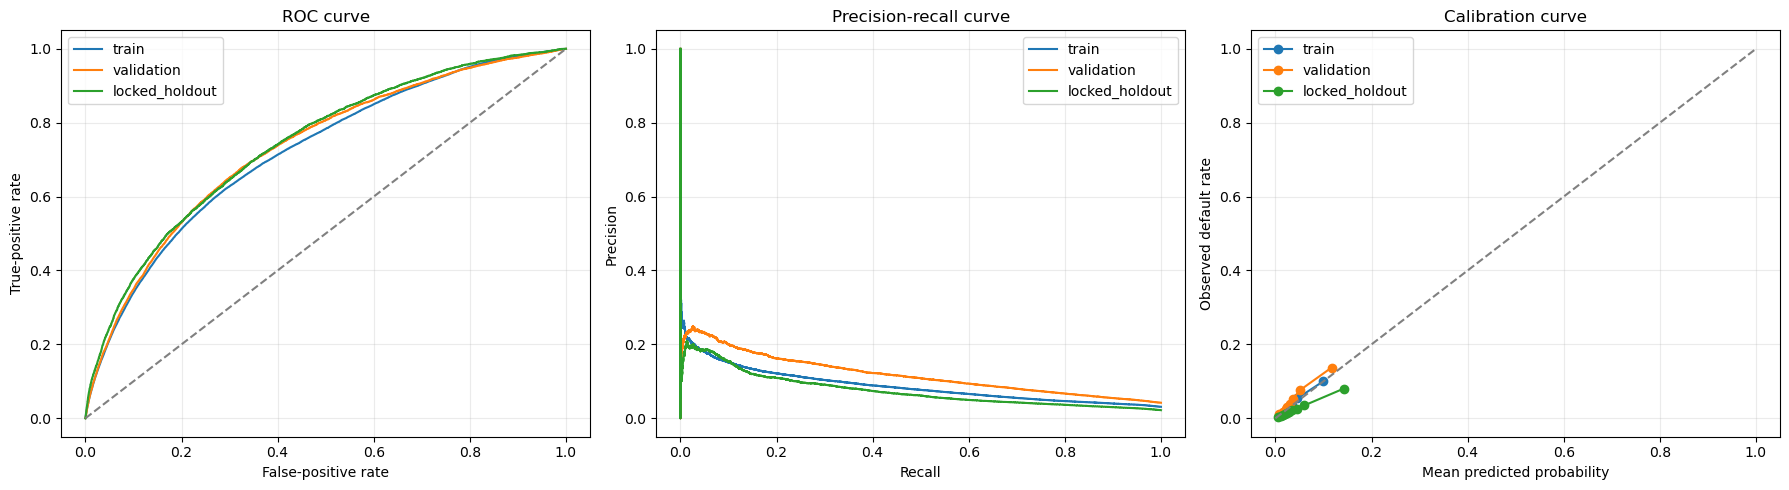

Weekly stability results:


,split,WEEK_NUM,applications,observed_default_rate,mean_predicted_probability,log_loss,roc_auc
0,train,0,16735,0.023902,0.028829,0.106136,0.701120
1,train,1,18841,0.025052,0.029368,0.111164,0.685184
2,train,2,17476,0.026608,0.029218,0.117938,0.667551
3,train,3,16108,0.026012,0.029574,0.114617,0.681340
4,train,4,14309,0.028234,0.029292,0.123364,0.676014
...,...,...,...,...,...,...,...
87,locked_holdout,87,17886,0.018394,0.040180,0.093695,0.739575
88,locked_holdout,88,14234,0.018617,0.042511,0.098040,0.748986
89,locked_holdout,89,13600,0.022721,0.044202,0.107038,0.734112
90,locked_holdout,90,12103,0.027266,0.045874,0.125061,0.705320


In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, log_loss, precision_score,
    recall_score, roc_auc_score, roc_curve, precision_recall_curve,
)
from sklearn.calibration import calibration_curve

if "sklearn_logistic_model" not in globals():
    raise NameError("Run the configurable logistic-regression training cell first.")

evaluation_model = sklearn_logistic_model
evaluation_training_rate = float(np.mean(y_train))

evaluation_splits = {
    "train": (X_train_selected, np.asarray(y_train, dtype=np.int64), train_df),
    "validation": (X_validation_selected, np.asarray(y_validation, dtype=np.int64), validation_df),
    "locked_holdout": (X_holdout_selected, np.asarray(y_holdout, dtype=np.int64), test_holdout_df),
}

def evaluate_probabilities(targets, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(np.int64)
    return {
        "rows": len(targets),
        "observed_default_rate": float(np.mean(targets)),
        "mean_predicted_probability": float(np.mean(probabilities)),
        "roc_auc": float(roc_auc_score(targets, probabilities)),
        "average_precision": float(average_precision_score(targets, probabilities)),
        "log_loss": float(log_loss(targets, probabilities)),
        "brier_score": float(brier_score_loss(targets, probabilities)),
        "accuracy_at_0_5": float(accuracy_score(targets, predictions)),
        "precision_at_0_5": float(precision_score(targets, predictions, zero_division=0)),
        "recall_at_0_5": float(recall_score(targets, predictions, zero_division=0)),
        "f1_at_0_5": float(f1_score(targets, predictions, zero_division=0)),
    }

evaluation_probability_by_split = {}
evaluation_metrics_rows = []
constant_baseline_metrics_rows = []
for split_name, (split_X, split_y, split_frame) in evaluation_splits.items():
    probabilities = evaluation_model.predict_proba(split_X)[:, 1]
    evaluation_probability_by_split[split_name] = probabilities
    model_metrics = evaluate_probabilities(split_y, probabilities)
    model_metrics["split"] = split_name
    model_metrics["model"] = "logistic_regression"
    evaluation_metrics_rows.append(model_metrics)
    constant_probabilities = np.full(len(split_y), evaluation_training_rate)
    baseline_metrics = evaluate_probabilities(split_y, constant_probabilities)
    baseline_metrics["split"] = split_name
    baseline_metrics["model"] = "constant_training_default_rate"
    constant_baseline_metrics_rows.append(baseline_metrics)

evaluation_metrics_df = pd.DataFrame(evaluation_metrics_rows + constant_baseline_metrics_rows)
evaluation_metrics_df = evaluation_metrics_df.set_index(["model", "split"])
print("Model and constant-baseline evaluation:")
display(evaluation_metrics_df.round(6))

print("Confusion matrices at threshold 0.5:")
for split_name, (_, split_y, _) in evaluation_splits.items():
    split_predictions = (evaluation_probability_by_split[split_name] >= 0.5).astype(np.int64)
    print(split_name)
    display(pd.DataFrame(
        confusion_matrix(split_y, split_predictions),
        index=["actual_0", "actual_1"],
        columns=["predicted_0", "predicted_1"],
    ))

def make_calibration_table(targets, probabilities, bins=10):
    calibration_frame = pd.DataFrame({"target": targets, "probability": probabilities})
    calibration_frame["bin"] = pd.qcut(
        calibration_frame["probability"], q=bins, duplicates="drop"
    )
    return calibration_frame.groupby("bin", observed=False).agg(
        applications=("target", "size"),
        mean_predicted_probability=("probability", "mean"),
        observed_default_rate=("target", "mean"),
        defaults=("target", "sum"),
    ).reset_index()

calibration_tables = {}
for split_name, (_, split_y, _) in evaluation_splits.items():
    calibration_tables[split_name] = make_calibration_table(
        split_y, evaluation_probability_by_split[split_name]
    )
print("Validation calibration table:")
display(calibration_tables["validation"].round(6))
print("Locked-holdout calibration table:")
display(calibration_tables["locked_holdout"].round(6))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for split_name, (_, split_y, _) in evaluation_splits.items():
    probabilities = evaluation_probability_by_split[split_name]
    fpr, tpr, _ = roc_curve(split_y, probabilities)
    precision, recall, _ = precision_recall_curve(split_y, probabilities)
    fraction_positive, mean_predicted = calibration_curve(split_y, probabilities, n_bins=10, strategy="quantile")
    axes[0].plot(fpr, tpr, label=split_name)
    axes[1].plot(recall, precision, label=split_name)
    axes[2].plot(mean_predicted, fraction_positive, marker="o", label=split_name)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_title("ROC curve")
axes[0].set_xlabel("False-positive rate")
axes[0].set_ylabel("True-positive rate")
axes[1].set_title("Precision-recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[2].set_title("Calibration curve")
axes[2].set_xlabel("Mean predicted probability")
axes[2].set_ylabel("Observed default rate")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()
plt.show()

weekly_rows = []
for split_name, (_, split_y, split_frame) in evaluation_splits.items():
    probabilities = evaluation_probability_by_split[split_name]
    weekly_frame = pd.DataFrame({
        "WEEK_NUM": split_frame["WEEK_NUM"].to_numpy(),
        "target": split_y,
        "probability": probabilities,
    })
    for week_number, week_group in weekly_frame.groupby("WEEK_NUM", sort=True):
        week_auc = np.nan if week_group["target"].nunique() < 2 else roc_auc_score(week_group["target"], week_group["probability"])
        weekly_rows.append({
            "split": split_name,
            "WEEK_NUM": week_number,
            "applications": len(week_group),
            "observed_default_rate": week_group["target"].mean(),
            "mean_predicted_probability": week_group["probability"].mean(),
            "log_loss": log_loss(week_group["target"], week_group["probability"], labels=[0, 1]),
            "roc_auc": week_auc,
        })
weekly_stability_df = pd.DataFrame(weekly_rows)
print("Weekly stability results:")
display(weekly_stability_df.round(6))
